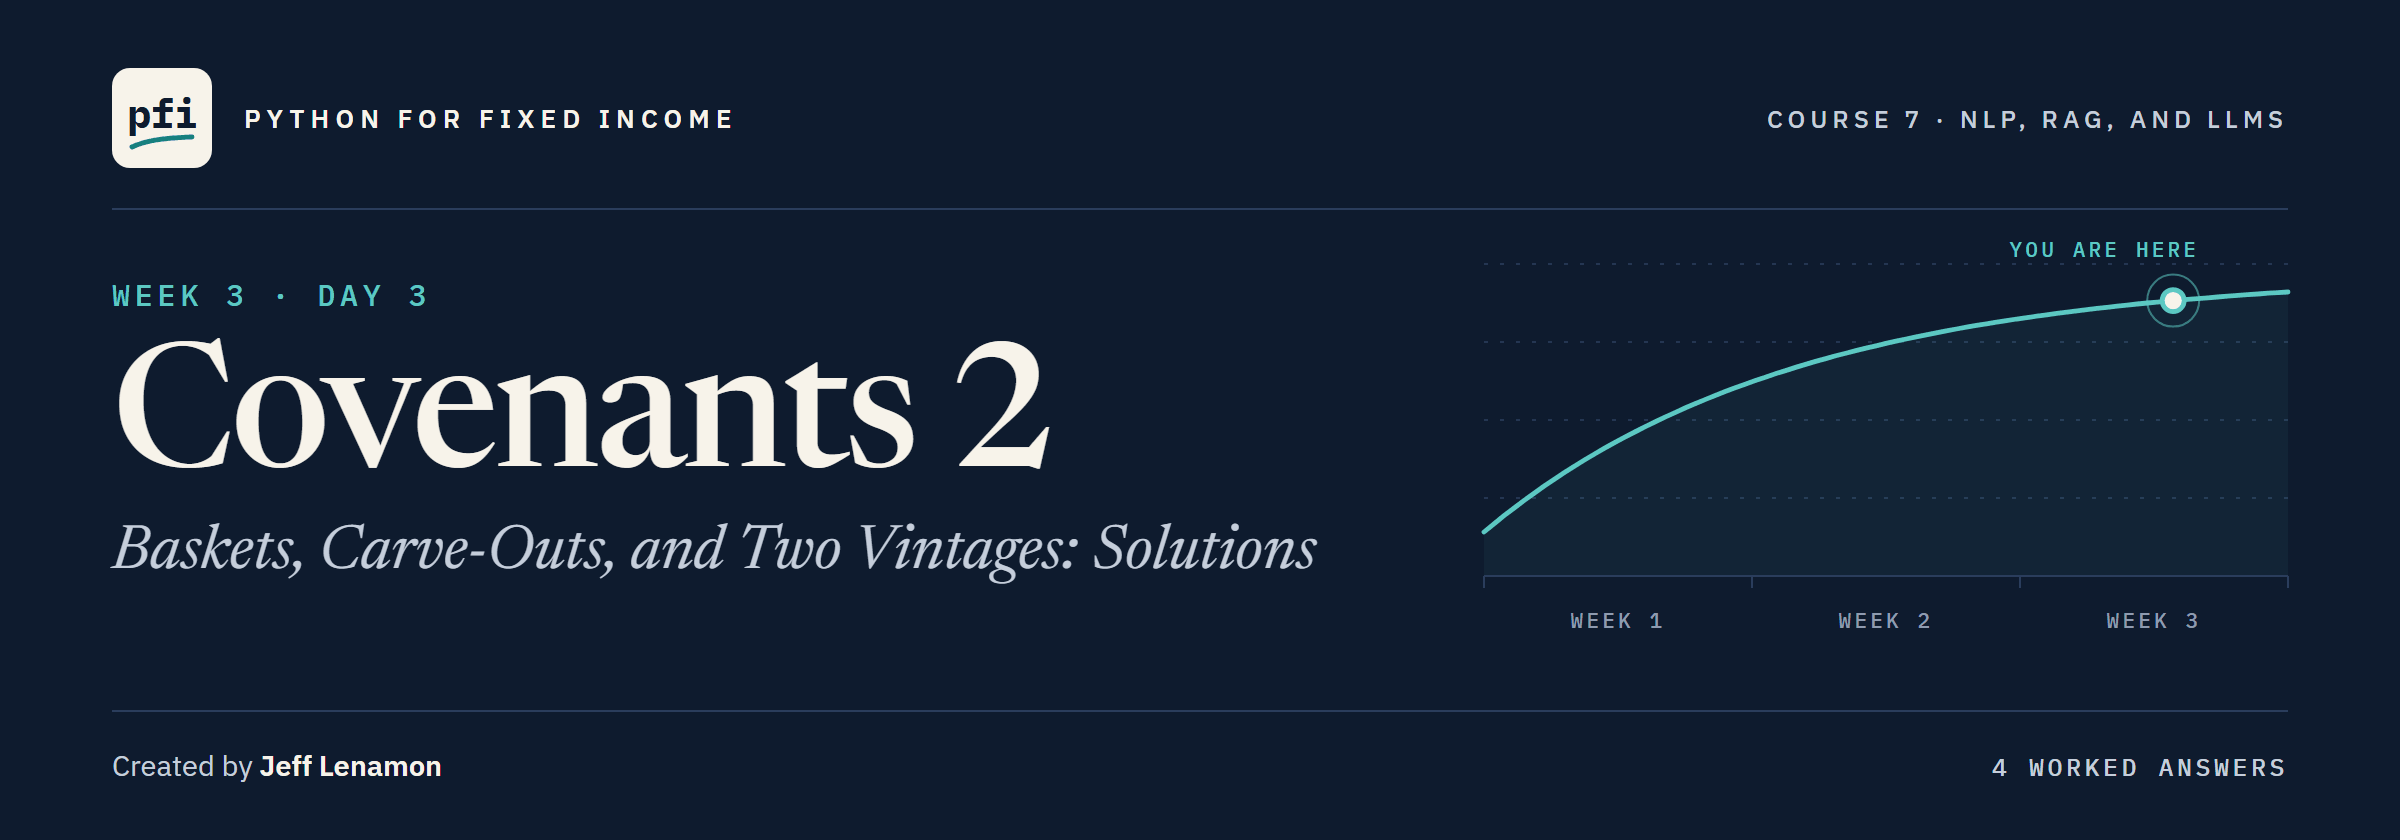

# Covenants 2: Baskets, Carve-Outs, and Two Vintages: Solutions

Week 3, Day 3. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day3/13_covenants_2_baskets_carve_outs_and_two_vintages_solutions.ipynb)

# Problem Statement

## Business Context

A credit desk records the baskets of the notes it follows: how much more debt, liens and payouts, beyond the ratio test.
Today it sets a 2006 indenture beside Day 12's 2021 indenture in one table, and reads a table from a PDF page.
Both indentures and the PDF print are public records, quoted for descriptive extraction.
Every response was sent by the course on 2026-10-08 and saved, and the notebook replays it.
A comparison states what each document writes and where, never which terms are preferable.
Nothing is fitted, so nothing is split; every prompt sentence was chosen on the 2021 indenture.

## Objectives

Read a covenant as a prohibition, a ratio test, permissions and carve-outs.
List every dollar amount and grower basket of an indenture with a regular expression.
Set two indentures' baskets side by side, clause by clause, and check a model's baskets against code's list.
Run a second indenture through the same schema and checks, and add a written form of a number it needs.
Read a PDF page as text and as an image, and check every row that comes back.
Choose the route from text or from pixels.

## Data Dictionary

`course7_indentures/boyd_2021.txt`: Day 1's indenture, "the 2021 indenture" here.

`course7_indentures/levi_2006.txt`: "the 2006 indenture", made by Day 9's `html_to_text` from the exhibit as filed.

`course7_boyd_2021_indenture.pdf`: the course's print of the 2021 indenture's SEC copy, 132 pages, counted from 0.

`course7_llm_responses/day13/<key>.json` and `day12/<key>.json`: saved responses with Day 11's fields.

Made in this notebook:

1. `DOCS`: each indenture's text, sections and definitions under one key, `"boyd"` or `"levi"`
2. the amounts table of `basket_amounts`, one row per dollar amount: `section`, `kind` ("amount" or "greater of"), `amount_usd`, `percent`, `percent_of`, `written`
3. the comparable table: each checked value by covenant kind and document

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# Colab does not come with pypdf or pypdfium2: this installs them there (on your machine, requirements.txt already did)
import sys
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install --quiet pypdf==6.19.0")
    get_ipython().run_line_magic("pip", "install --quiet pypdfium2==5.14.0")

# text, files, fingerprints, word-by-word comparison and the one kind of text a field may hold
import base64
import difflib
import hashlib
import io
import json
import re
import unicodedata
from typing import Literal

# data, charts and the dropdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# the client for a language model, Course 3's reader of a .env file, the schema library and the two PDF libraries
import openai
from dotenv import dotenv_values
from pydantic import BaseModel
from pypdf import PdfReader
import pypdfium2

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

Day 1's `data_file`: the repo's path on your machine, a copy downloaded once in Colab.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

## Day 1's Text Tools

Day 1 wrote these, with `section_text` from its Exercise 3; `levi_source` and `pdf_source` follow `boyd_source`'s form.

In [4]:
# Day 1's look-alike map, normalize_text, the three source lines, the sections and one section's text
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}
SECTION_PATTERN = r"^(?:Section|SECTION) (?P<number>\d+\.\d+)\.? (?P<title>[A-Z\[][^\n]*?)\.?$"


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")


def levi_source(section=None):
    """Print the source line of the Levi indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Levi Strauss & Co., Indenture dated as of March 17, 2006, 8-7/8% Senior Notes due 2016, Exhibit 4.1 to "
          f"the 8-K filed 2006-03-17, accession 0000950134-06-005445{where}.")


def pdf_source(page):
    """Print the source line of one page of the course's PDF print of the Boyd indenture."""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495, the course's PDF print of the SEC copy, page index {page} "
          "(pages counted from 0).")


def find_sections(text):
    """The sections of an indenture, in the order of the text: number as text, title, start and end."""
    found = {}
    for heading in re.finditer(SECTION_PATTERN, text, flags=re.MULTILINE):
        found[heading["number"]] = {"number": heading["number"], "title": heading["title"], "start": heading.start()}
    sections = pd.DataFrame(found.values()).sort_values("start", ignore_index=True)
    sections["end"] = sections["start"].shift(-1, fill_value=len(text))
    return sections


def section_text(text, sections, number):
    """The text of one section of an indenture, from its heading to the next section's heading."""
    row = sections.set_index("number").loc[number]
    return text[row["start"]:row["end"]]

## Day 11's Request Tools

Day 11's key cell word for word, then its request tools, with `ask` reading `day13`'s saved files.

In [5]:
# the key: the environment, then Colab's Secrets panel, then Course 3's .env file; never printed
key = os.environ.get("OPENROUTER_API_KEY")
if "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = key or userdata.get("OPENROUTER_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None
key = key or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENROUTER_API_KEY")
client = openai.OpenAI(base_url="https://openrouter.ai/api/v1", api_key=key, max_retries=0) if key else None
print(f"OpenRouter key loaded: {client is not None}. Mode: {'live' if client is not None else 'replay'}.")

OpenRouter key loaded: False. Mode: replay.


In [6]:
# Day 11's request tools: the system prompt, the two models, their prices, the request key, ask and the LLM line
SYSTEM_PROMPT = (
    "You extract information from the document text in the user message. Quote the text exactly, character for "
    "character, and give the number of the section each quote comes from. Write every number exactly as the text "
    "writes it. If the text does not answer the question, reply NOT IN TEXT. If the user asks for an opinion, a "
    "grade, a comparison of quality, an ordering of securities or issuers, advice about trading, or a view about "
    "the future, reply exactly: REFUSED: this course asks only what the document says"
)
TEXT_MODEL = "nvidia/nemotron-3-super-120b-a12b:free"
FALLBACK_MODEL = "google/gemini-2.5-flash-lite"
NO_REASONING = {"reasoning": {"enabled": False}}
PRICES = {TEXT_MODEL: ("0", "0"), FALLBACK_MODEL: ("0.0000001", "0.0000004")}


def request_key(request):
    """The SHA-256 fingerprint of a request, as 64 hex characters."""
    text = json.dumps(request, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode("ascii")).hexdigest()


def ask(user_message, model=TEXT_MODEL, extra_body=NO_REASONING, temperature=0.0, seed=SEED, max_tokens=2000,
        response_format=None, provider="openrouter", day="day13"):
    """The response to one request: the course's saved one when no key is loaded, else one sent live."""
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_message}]
    params = {"temperature": temperature, "seed": seed, "max_tokens": max_tokens, "response_format": response_format,
              "extra_body": extra_body}
    request = {"provider": provider, "model": model, "messages": messages, "params": params}
    # the notebook's one client is OpenRouter's, so a request on another route always replays
    if client is None or provider != "openrouter":
        saved = Path(data_file(f"course7_llm_responses/{day}/{request_key(request)}.json"))
        return json.loads(saved.read_text(encoding="utf-8"))
    # response_format is sent only when it is set
    options = {} if response_format is None else {"response_format": response_format}
    sent = client.chat.completions.create(model=model, messages=messages, temperature=temperature, seed=seed,
                                          max_tokens=max_tokens, extra_body=extra_body, **options)
    return {"content": sent.choices[0].message.content, "model": sent.model, "provider": sent.model_dump().get("provider"),
            "usage": sent.usage.model_dump(), "finish_reason": sent.choices[0].finish_reason, "recorded": "live",
            "request": request}


def llm_line(response):
    """Print the model, the temperature and seed, and where the response came from."""
    settings = response["request"]["params"]
    if response["recorded"] == "live":
        where = "live."
    elif client is None:
        where = f"saved response recorded {response['recorded']}; replayed (no key loaded)."
    else:
        where = f"saved response recorded {response['recorded']}; replayed (not the client's route)."
    print(f"Model {response['request']['model']}, temperature {settings['temperature']}, seed {settings['seed']}; {where}")

## Day 12's Extraction Tools

Day 12's definitions, schema and checks, repeated as two cells.
The keyword `doc=` is the one change: it picks the indenture from `DOCS`, made below, so every message and every key is Day 12's.

In [7]:
# Day 12's definitions, the defined terms a text uses, the four classes, the schema as JSON and its three sentences
def definitions_dict(text, sections):
    """Every definition in Section 1.01: the quoted term, then its paragraphs up to the next quoted term."""
    part = normalize_text(section_text(text, sections, "1.01"))
    found = list(re.finditer(r'^"(?P<term>[A-Z0-9][^"\n]{0,100}?),?"', part, flags=re.MULTILINE))
    starts = [match.start() for match in found] + [len(part)]
    return {match["term"]: part[start:end].strip() for match, start, end in zip(found, starts[:-1], starts[1:])}


def terms_used(text, definitions, depth=1):
    """The defined terms a text uses, in order of first use; depth=2 adds the terms their definitions use."""
    first = {}
    for term in definitions:
        found = re.search(rf"(?<!\w){re.escape(term)}(?!\w)", text)
        if found:
            first[term] = found.start()
    used = sorted(first, key=lambda term: (first[term], term))
    if depth == 2:
        for term in list(used):
            used += [extra for extra in terms_used(definitions[term], definitions) if extra not in used]
    return used


class Quote(BaseModel):
    """A quotation from the document and the number of the section it comes from."""
    section: str
    text: str


class RatioTest(BaseModel):
    """A ratio test as the document states it: its name, its level, its unit ("x"), and its direction."""
    name: str
    threshold: float
    unit: str
    direction: str
    quote: Quote


class Basket(BaseModel):
    """A permission to incur, pay, or grant up to an amount: fixed, a percentage of a defined term, or the greater
    of the two."""
    name: str
    fixed_amount_usd: int | None
    percent: float | None
    percent_of: str | None
    greater_of: bool
    quote: Quote


class Covenant(BaseModel):
    """One covenant: its kind, its section, its title, its ratio test if it has one, and its baskets."""
    kind: Literal["indebtedness", "restricted_payments", "liens", "asset_sales", "change_of_control",
                  "affiliate_transactions", "covenant_suspension"]
    section: str
    title: str
    ratio_test: RatioTest | None
    baskets: list[Basket]
    quote: Quote


SCHEMA = json.dumps(Covenant.model_json_schema())
JSON_OBJECT = {"type": "json_object"}
CHANGES = [("Copy every quote exactly as the text writes it, one clause of at most 60 words, and give its section as the "
            "number of a section heading, such as 4.12 or 1.01, never a clause such as 4.12(b)."),
           ('Write every number as the text writes it: a dollar amount as a whole number of dollars in fixed_amount_usd, '
            'a percentage in percent, a ratio such as 2.0 to 1.0 as threshold 2.0 with unit "x", and fill every '
            'amount the quote holds.'),
           ("List only the baskets that state a dollar amount or a percentage, and use null for a field the text does "
            "not state. If the section holds no covenant of this kind, reply NOT IN TEXT.")]

In [8]:
# Day 12's message, extraction and checks; doc= picks the indenture
def instruction(number, kind, changes=()):
    """What to extract and the schema, then each added sentence on its own line."""
    text = (f'Extract the covenant of Section {number} of the indenture below, of kind "{kind}", as one JSON object '
            f"that fits this JSON schema:\n{SCHEMA}")
    return text + "".join("\n" + sentence for sentence in changes)


def covenant_message(number, kind, changes=(), with_definitions=True, doc="boyd"):
    """The user message: the instruction, the definitions the section uses, then the section's exact text."""
    text, sections, definitions = DOCS[doc]
    body = section_text(text, sections, number)
    parts = [instruction(number, kind, changes)]
    if with_definitions:
        used = terms_used(body, definitions)
        parts.append(f"The definitions of Section 1.01 that Section {number} uses ({len(used)} terms):\n"
                     + "\n".join(definitions[term] for term in used))
    parts.append(f"Section {number} of the indenture:\n{body}")
    return "\n\n".join(parts)


def extract(number, kind, changes=(), model=TEXT_MODEL, with_definitions=True, doc="boyd"):
    """The response to one extraction request; the fallback is sent without NO_REASONING, as recorded."""
    extra_body = NO_REASONING if model == TEXT_MODEL else None
    return ask(covenant_message(number, kind, changes, with_definitions, doc), model=model, extra_body=extra_body,
               max_tokens=4000, response_format=JSON_OBJECT)


def number_forms(value, unit):
    """The ways the text may write a number, with no dollar sign."""
    if unit == "USD":
        forms = [f"{int(value):,}"]
        if value >= 1e6:
            forms.append(f"{value / 1e6:,g} million")
        if value >= 1e9:
            forms.append(f"{value / 1e9:g} billion")
    elif unit == "%":
        forms = [f"{value:g}%", f"{value:.1f}%"]
    else:
        forms = [f"{value:.1f} to 1.0", f"{value:.2f} to 1.00", f"{value:g} to 1"]
    return [form for i, form in enumerate(forms) if form not in forms[:i]]


def number_found(value, unit, quote):
    """True when one written form of the number stands whole in the quote."""
    for form in number_forms(value, unit):
        if re.search(r"(?<![\d.,])" + re.escape(form) + r"(?![.,]?\d)", quote):
            return True
    return False


def plain(text):
    """Text through normalize_text, every run of white space one space."""
    return re.sub(r"\s+", " ", normalize_text(text))


def covenant_values(covenant):
    """(field, value, unit, quote) for the ratio test and every basket amount and percentage."""
    values = []
    if covenant.ratio_test is not None:
        values.append(("ratio_test", covenant.ratio_test.threshold, "x", covenant.ratio_test.quote))
    for basket in covenant.baskets:
        if basket.fixed_amount_usd is not None:
            values.append((basket.name + ": fixed_amount_usd", basket.fixed_amount_usd, "USD", basket.quote))
        if basket.percent is not None:
            values.append((basket.name + ": percent", basket.percent, "%", basket.quote))
    return values


def check_extraction(covenant, doc="boyd"):
    """The checked table of one covenant: one row per number, its section, and the three checks."""
    text, sections, definitions = DOCS[doc]
    rows = []
    for field, value, unit, quote in covenant_values(covenant):
        exists = quote.section in set(sections["number"])
        quote_found = exists and plain(quote.text) in plain(section_text(text, sections, quote.section))
        number = number_found(value, unit, plain(quote.text))
        rows.append([covenant.kind, field, value, unit, quote.section, exists, quote_found, number, exists and quote_found and number])
    return pd.DataFrame(rows, columns=["covenant", "field", "value", "unit", "section", "section_exists", "quote_found", "number_found", "passed"])

# Loading the Data

## Two Indentures

In [9]:
# source text: quoted as published
# each indenture through normalize_text, with its sections and definitions, under one key
def load(name):
    """An indenture's text through normalize_text, its sections and its definitions."""
    text = normalize_text(Path(data_file(f"course7_indentures/{name}.txt")).read_text(encoding="utf-8"))
    sections = find_sections(text)
    return text, sections, definitions_dict(text, sections)


DOCS = {"boyd": load("boyd_2021"), "levi": load("levi_2006")}
VINTAGE = {"boyd": "2021 indenture", "levi": "2006 indenture"}
boyd, boyd_sections, boyd_definitions = DOCS["boyd"]
levi, levi_sections, levi_definitions = DOCS["levi"]
sizes = pd.DataFrame({VINTAGE[doc]: {"characters": len(text), "words": len(text.split()), "sections": len(sections),
                                     "definitions": len(definitions),
                                     "Article 4 sections": int(sections["number"].str.startswith("4.").sum())}
                      for doc, (text, sections, definitions) in DOCS.items()})
print(sizes.to_string())
boyd_source()
levi_source()

                    2021 indenture  2006 indenture
characters                  392021          289925
words                        63595           47107
sections                       107              85
definitions                    148              95
Article 4 sections              20              13
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.
Source: Levi Strauss & Co., Indenture dated as of March 17, 2006, 8-7/8% Senior Notes due 2016, Exhibit 4.1 to the 8-K filed 2006-03-17, accession 0000950134-06-005445.


The same Day 1 and Day 12 functions read both texts, unchanged; labels name each document by its year.

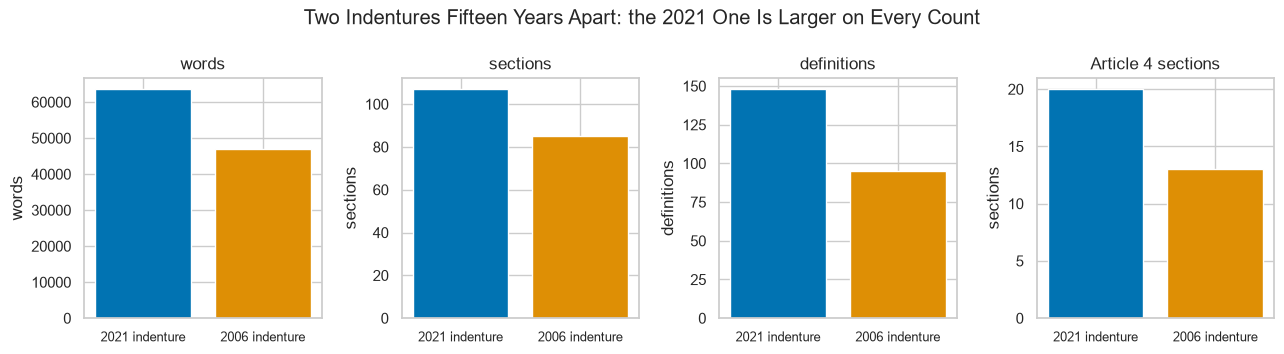

In [10]:
# the two documents measure by measure, one panel each
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, measure, unit in zip(axes, ["words", "sections", "definitions", "Article 4 sections"],
                             ["words", "sections", "definitions", "sections"]):
    ax.bar(sizes.columns, sizes.loc[measure], color=["C0", "C1"])
    ax.set(title=measure, ylabel=unit)
    ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Two Indentures Fifteen Years Apart: the 2021 One Is Larger on Every Count")
plt.tight_layout()
plt.show()

## Article 4 in Each

The 2006 heading lines run on into each section's first sentence, so its titles print cut at the first ". ", for display only.

In [11]:
# source text: quoted as published
# the schema's seven covenant kinds against each document's section and title
KINDS = {"indebtedness": ("4.12", "4.04"), "restricted_payments": ("4.15", "4.05"), "liens": ("4.14", "4.06"),
         "asset_sales": ("4.11", "4.07"), "change_of_control": ("4.10", "4.12"),
         "affiliate_transactions": ("4.17", "4.09"), "covenant_suspension": ("4.20", "4.01")}
titles = {doc: {number: title.split(". ")[0] for number, title in zip(sections["number"], sections["title"])}
          for doc, (text, sections, definitions) in DOCS.items()}
for kind, (new, old) in KINDS.items():
    print(f"{kind:23} | 2021 {new} {titles['boyd'][new]:42} | 2006 {old} {titles['levi'][old]}")
boyd_source()
levi_source()

indebtedness            | 2021 4.12 Limitation on Indebtedness                 | 2006 4.04 Limitation on Debt
restricted_payments     | 2021 4.15 Limitation on Restricted Payments          | 2006 4.05 Limitation on Restricted Payments
liens                   | 2021 4.14 Limitation on Liens                        | 2006 4.06 Limitation on Liens
asset_sales             | 2021 4.11 Asset Sales                                | 2006 4.07 Limitation on Asset Sales
change_of_control       | 2021 4.10 Change of Control                          | 2006 4.12 Change of Control
affiliate_transactions  | 2021 4.17 Limitation on Transaction with Affiliates  | 2006 4.09 Limitation on Transactions with Affiliates
covenant_suspension     | 2021 4.20 Certain Suspended Covenants                | 2006 4.01 Covenant Suspension
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.
Source: Levi Strauss & Co., I

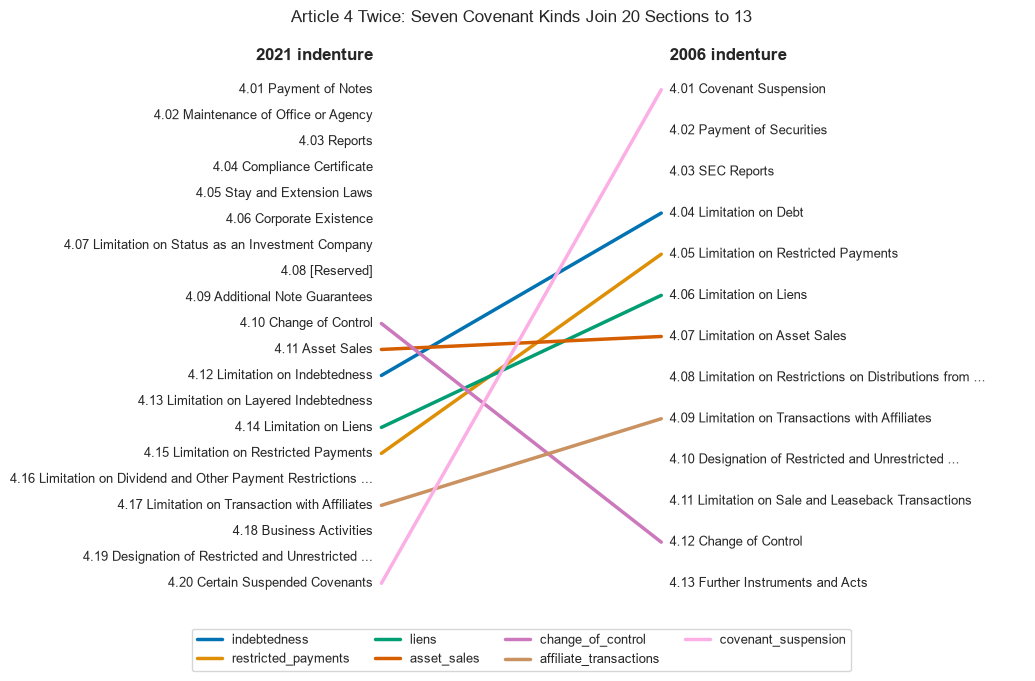

In [12]:
# Article 4 of each as two columns of sections, one line for each kind the schema names
fig, ax = plt.subplots(figsize=(13, 7.5))
place = {}
for x, doc, align in [(0, "boyd", "right"), (1, "levi", "left")]:
    article = [number for number in titles[doc] if number.startswith("4.")]
    for i, number in enumerate(article):
        place[doc, number] = -i / (len(article) - 1)
        # a title past 54 characters is cut at its last whole word, and " ..." marks the cut
        title = titles[doc][number] if len(titles[doc][number]) <= 54 else titles[doc][number][:54].rsplit(" ", 1)[0] + " ..."
        ax.text(x - 0.03 if x == 0 else x + 0.03, place[doc, number], f"{number} {title}", ha=align, va="center", fontsize=9)
for i, (kind, (new, old)) in enumerate(KINDS.items()):
    ax.plot([0, 1], [place["boyd", new], place["levi", old]], color=f"C{i}", lw=2.5, label=kind)
ax.text(-0.03, 0.06, VINTAGE["boyd"], ha="right", weight="bold")
ax.text(1.03, 0.06, VINTAGE["levi"], ha="left", weight="bold")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
ax.set(xlim=(-1.3, 2.3), ylim=(-1.05, 0.12), title="Article 4 Twice: Seven Covenant Kinds Join 20 Sections to 13")
ax.set_axis_off()
plt.show()

Indebtedness is 4.12 in 2021 and 4.04 in 2006, where 4.12 is change of control.

**The covenant kind lines the two documents up, never the section number or the title.**

# How a Covenant Is Built

## Section 4.12, Part by Part

A covenant opens with a **prohibition**, "shall not ... Incur any Indebtedness", lets ratio debt through its ratio test (Day 12), then lists **permissions**.
`clauses(text, labels)` finds each label at a line start after the label before it, so a sub-clause inside a clause is skipped.

In [13]:
# the labels of a numbered list, and the clauses of a text that carry them in order, each running to the next
ROMAN = "i ii iii iv v vi vii viii ix x xi xii xiii xiv xv xvi xvii xviii xix xx".split()
LETTERS = list("abcdefghijklmnopqrstuvwxyz") + [letter * 2 for letter in "abcdefghijkl"]


def clauses(text, labels):
    """Each label's clause in order: a label counts only at a line start, after the label before it."""
    starts = {}
    for found in re.finditer(r"^\(([a-z]+)\) ", text, flags=re.MULTILINE):
        if len(starts) < len(labels) and found[1] == labels[len(starts)]:
            starts[found[1]] = found.start()
    ends = list(starts.values())[1:] + [len(text)]
    return {label: text[start:end].strip() for (label, start), end in zip(starts.items(), ends)}

In [14]:
# source text: quoted as published
# Section 4.12's paragraphs (a) to (e), the first line of (a), then the start of each of (b)'s permissions
parts = clauses(section_text(boyd, boyd_sections, "4.12"), list("abcde"))
print({label: len(part) for label, part in parts.items()}, "characters")
print(parts["a"].split("\n")[0])
permissions = clauses(parts["b"], ROMAN)
for clause in permissions.values():
    print("   ", clause[:70])
print(re.search(r"^.*?will not be deemed to be an Incurrence of Indebtedness", parts["d"])[0])
boyd_source("4.12")

{'a': 2347, 'b': 6726, 'c': 1148, 'd': 1246, 'e': 355} characters
(a) The Company shall not, and shall not permit any Restricted Subsidiary to, Incur any Indebtedness; provided, however, that the Company or any Guarantor may Incur Indebtedness if the Company's Consolidated Fixed Charge Coverage Ratio would have been at least 2.0 to 1.0, after giving effect to:
    (i) Indebtedness of the Company represented by the Initial Notes and o
    (ii) Indebtedness of the Company or any Restricted Subsidiary outstand
    (iii) Indebtedness of the Company or any Restricted Subsidiary under C
    (iv) Indebtedness of the Company or a Restricted Subsidiary owing to a
    (v) Indebtedness of the Company or a Restricted Subsidiary under Inter
    (vi) Indebtedness of the Company or a Restricted Subsidiary under Curr
    (vii) Indebtedness of the Company or any Restricted Subsidiary in conn
    (viii) Indebtedness of the Company or any Restricted Subsidiary outsta
    (ix) Indebtedness (including Capi

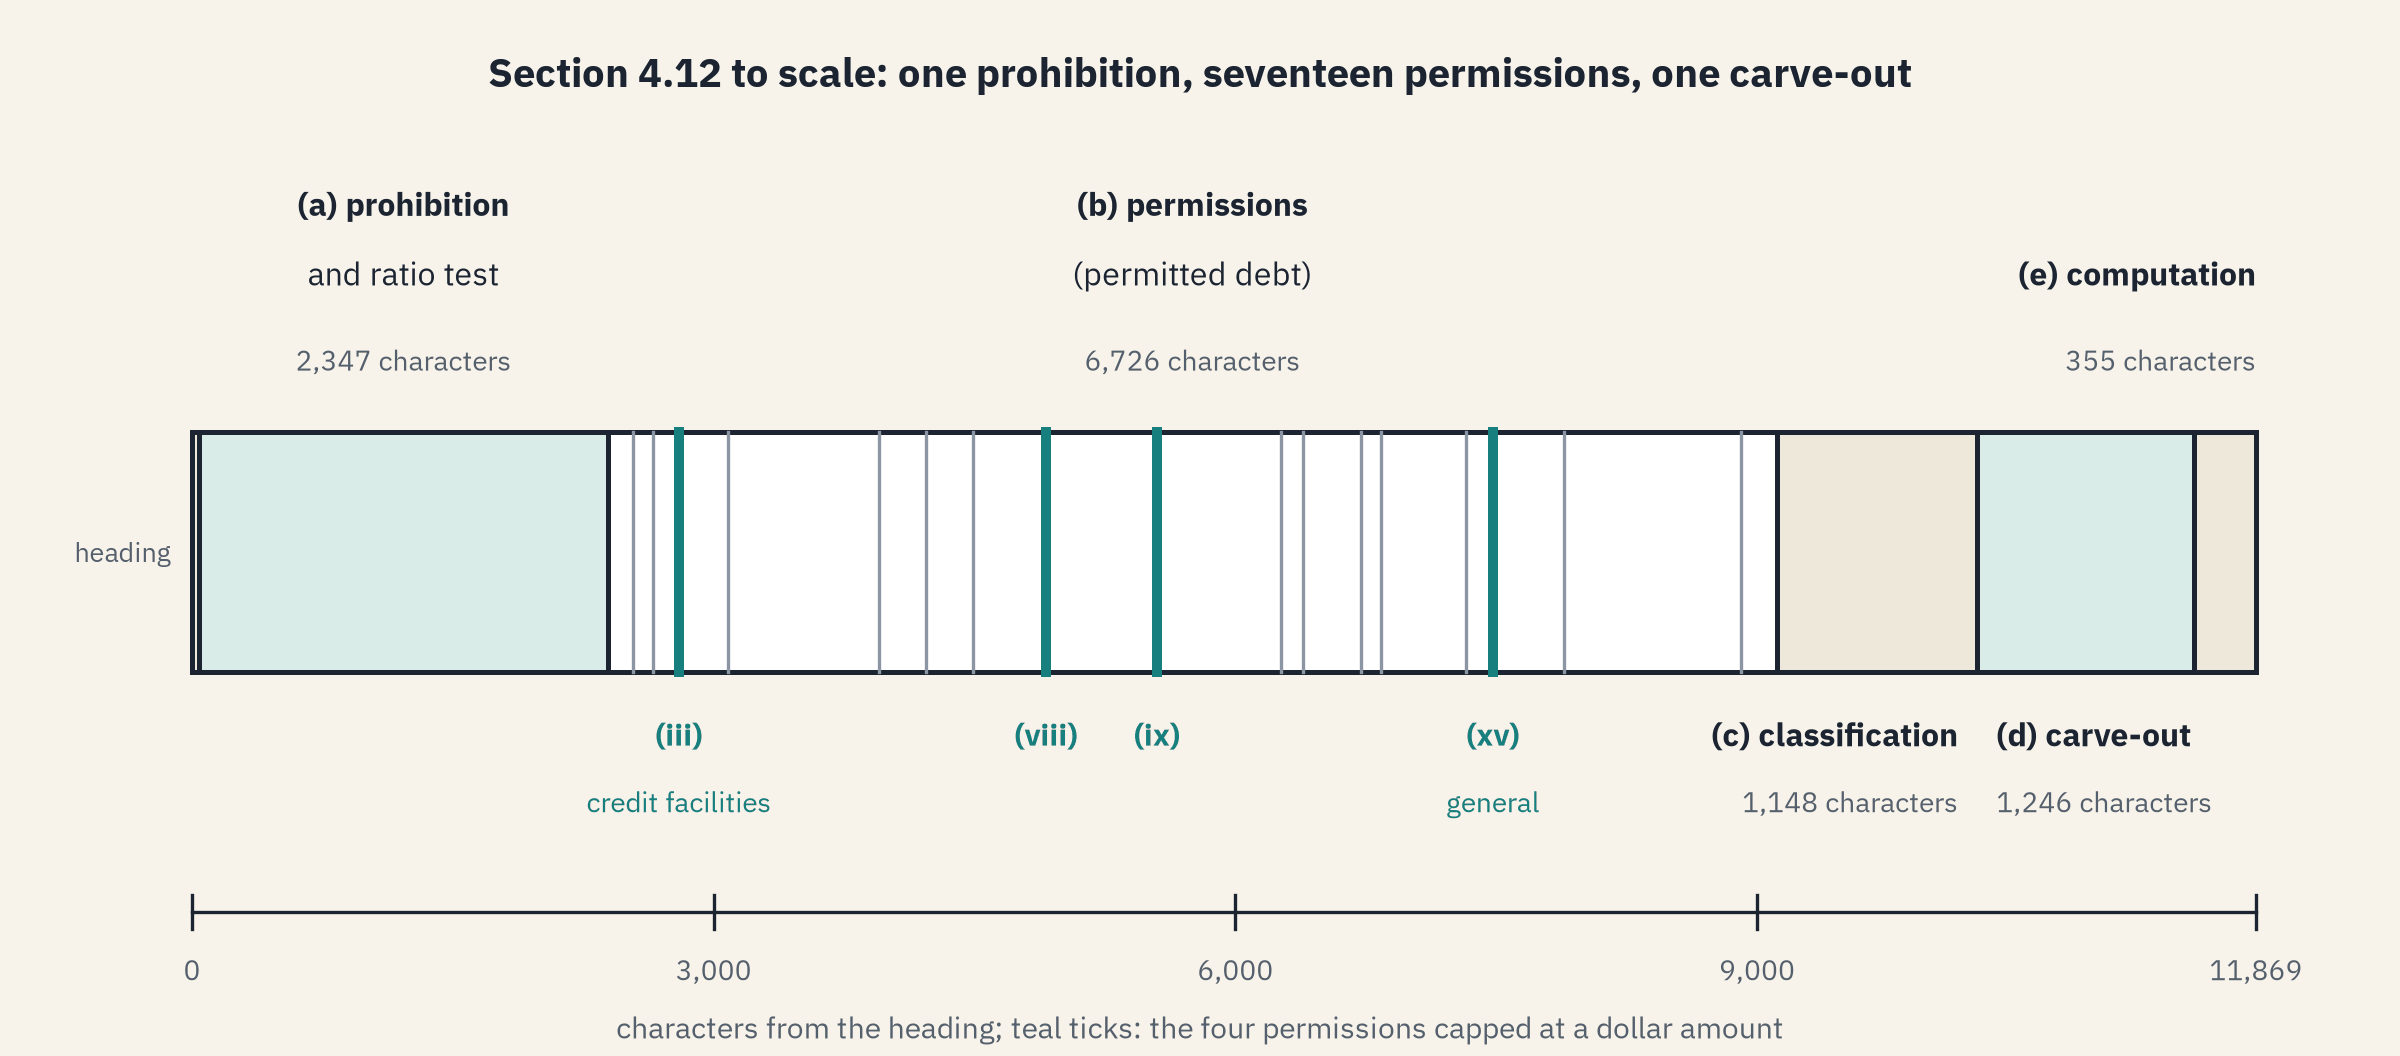

(a) is the prohibition with its test; (b) lists **permitted debt**, debt allowed whatever the ratio.

Four permissions cap debt at a dollar amount: (iii) credit facilities, (viii), (ix) and (xv), the general one.

(xiii) names `$1.00` only as a test, and (i), the notes themselves, states no amount.

(d) is a **carve-out**: interest paid in kind and the like "will not be deemed to be an Incurrence of Indebtedness" at all.

## The 2006 Debt Covenant

The 2006 indenture writes its prohibition, its test and its list in one section, 4.04, and defines "Permitted Debt" there.

In [15]:
# source text: quoted as published
# 4.04's ratio test, where "Permitted Debt" is defined, then the first 70 characters of each of its clauses
body_404 = section_text(levi, levi_sections, "4.04")
print(re.search(r"the Consolidated Fixed Charges Coverage Ratio would be greater than [\d.]+ to [\d.]+", body_404)[0])
print('"Permitted Debt" defined in Section 1.01', "Permitted Debt" in levi_definitions, "| inside 4.04",
      '"Permitted Debt" means' in body_404)
permitted_debt = clauses(body_404[body_404.index('"Permitted Debt" means'):], LETTERS)
for clause in permitted_debt.values():
    print("   ", clause[:70])
levi_source("4.04")

the Consolidated Fixed Charges Coverage Ratio would be greater than 2.00 to 1.00
"Permitted Debt" defined in Section 1.01 False | inside 4.04 True
    (a) Debt of the Company evidenced by the Original Securities and the €
    (b) Debt of the Company or a Restricted Subsidiary Incurred under any 
    (c) Debt of the Company owing to and held by any Restricted Subsidiary
    (d) Debt of a Restricted Subsidiary outstanding on the date on which t
    (e) Debt under Interest Rate Agreements entered into by the Company or
    (f) Debt under Currency Exchange Protection Agreements entered into by
    (g) Debt under Commodity Price Protection Agreements entered into by t
    (h) Debt in connection with one or more standby letters of credit or p
    (i) Debt arising from agreements of the Company or a Restricted Subsid
    (j) Debt outstanding on the Issue Date not otherwise described in clau
    (k) Debt of the Company or a Restricted Subsidiary in an aggregate pri
    (l) Permitted Refinancin

## Where the Liens Permissions Live

In [16]:
# source text: quoted as published
# "Permitted Liens" in Section 1.01 of each document: how many clauses, from the first label to the last
for doc, (text, sections, definitions) in DOCS.items():
    liens_clauses = clauses(definitions["Permitted Liens"], LETTERS)
    print(VINTAGE[doc], "|", len(liens_clauses), "clauses, from", list(liens_clauses)[0], "to", list(liens_clauses)[-1])

2021 indenture | 38 clauses, from a to ll
2006 indenture | 20 clauses, from a to t


Both documents list their liens permissions in Section 1.01, as Day 12 found.

**Fifteen years apart, both debt covenants have the same shape: a prohibition, a test and a numbered list, and the list holds the numbers.**

# Every Dollar Amount, Read by Code

## The Pattern

Day 12's `AMOUNT` finds a written dollar amount, and `dollars` turns one into whole US dollars.
`GROWER` finds a grower basket: "greater of", an optional mark such as "(A) ", an amount, "and" or "or", another optional mark, then a percentage "of" a capitalised term.

In [17]:
# a written amount, its value in whole dollars, and the grower pattern built around it
AMOUNT = r"\$\d{1,3}(?:,\d{3})*(?:\.\d+)?(?: (?:million|billion))?"
GROWER = (r"greater of (?:\([A-Za-z]\) )?(?P<amount>" + AMOUNT + r"),? (?:and|or) (?:\([A-Za-z]\) )?"
          r"(?P<percent>\d+(?:\.\d+)?)% of (?:the )?(?:Company's )?(?P<term>[A-Z][a-z]+(?: [A-Z][a-z]+)*)")


def dollars(written):
    """A written dollar amount in whole dollars: "$1.6 billion" is 1600000000."""
    number = float(re.sub(r"[$,]| million| billion", "", written))
    scale = 1_000_000_000 if written.endswith("billion") else 1_000_000 if written.endswith("million") else 1
    return int(round(number * scale))


# three written amounts, then the grower in clause (xv)
print([dollars(written) for written in ["$430,000,000", "$3.5 billion", "$12.5 million"]])
print(re.search(GROWER, permissions["xv"]).groupdict())

[430000000, 3500000000, 12500000]
{'amount': '$430,000,000', 'percent': '7.5', 'term': 'Consolidated Total Assets'}


## `basket_amounts`

One row per amount, section by section; a row is "greater of" when a grower opens with that amount.

In [18]:
# every dollar amount of an indenture, section by section, with the grower it opens if any
def basket_amounts(text, sections):
    """Every dollar amount of an indenture by section, with its percentage and term when it opens a grower."""
    rows = []
    for number, start, end in zip(sections["number"], sections["start"], sections["end"]):
        growers = {found.start("amount"): found for found in re.finditer(GROWER, text[start:end])}
        for found in re.finditer(AMOUNT, text[start:end]):
            grower = growers.get(found.start())
            rows.append({"section": number, "kind": "greater of" if grower else "amount", "amount_usd": dollars(found[0]),
                         "percent": float(grower["percent"]) if grower else None,
                         "percent_of": grower["term"] if grower else "", "written": found[0]})
    return pd.DataFrame(rows)


# the 2021 indenture: how many, its growers, and Section 4.12's amounts
amounts_2021 = basket_amounts(boyd, boyd_sections)
print(len(amounts_2021), "amounts |", amounts_2021["kind"].value_counts().to_dict())
print(amounts_2021[amounts_2021["kind"] == "greater of"].to_string(index=False))
print("4.12:", amounts_2021.loc[amounts_2021["section"] == "4.12", "written"].tolist())

57 amounts | {'amount': 51, 'greater of': 6}
section       kind  amount_usd  percent                percent_of      written
   1.01 greater of   855000000     15.0 Consolidated Total Assets $855,000,000
   1.01 greater of   570000000     10.0 Consolidated Total Assets $570,000,000
   1.01 greater of   430000000      7.5 Consolidated Total Assets $430,000,000
   4.11 greater of   285000000      5.0 Consolidated Total Assets $285,000,000
   4.12 greater of   285000000      5.0 Consolidated Total Assets $285,000,000
   4.12 greater of   430000000      7.5 Consolidated Total Assets $430,000,000
4.12: ['$3.5 billion', '$50,000,000', '$285,000,000', '$1.00', '$430,000,000']


Every grower is a percentage of Consolidated Total Assets: three in Section 1.01's definitions, one in 4.11 and two in 4.12.

4.12's `$3.5 billion` is a plain amount here: its alternative is "4.5 times" a measure, not a percentage.

**Predict 1**

The pattern finds 6 growers in the 2021 indenture.

Q. How many will it find in the 2006 indenture? Write down a number.

## The Same Pattern on the 2006 Text

In [19]:
# source text: quoted as published
# the 2006 indenture's amounts and growers, then every "greater of" the text writes, line breaks shown as /
amounts_2006 = basket_amounts(levi, levi_sections)
print(len(amounts_2006), "amounts |", amounts_2006["kind"].value_counts().to_dict())
for found in re.finditer("greater of", levi):
    print("   ", levi[found.start():found.start() + 64].replace("\n", " / "))
levi_source()

47 amounts | {'amount': 47}
    greater of: / (1) the Fair Market Value of the Property subject to
    greater of (i) the maximum liquidation value of such Preferred S
    greater of: / (1) $1.6 billion, which amount shall be permanently 
    greater of (1) 1.0% of the principal amount of such Security at 
    greater of (1) 1.0% of the principal amount of such Security at 
Source: Levi Strauss & Co., Indenture dated as of March 17, 2006, 8-7/8% Senior Notes due 2016, Exhibit 4.1 to the 8-K filed 2006-03-17, accession 0000950134-06-005445.


None: two of the five "greater of" end in a colon, and one of those puts `$1.6 billion` on the next line, after "(1)".

So that amount counts as plain; the other four compare things that are not dollar amounts.

The 2006 text also writes one amount in euros, in "Permitted Debt" (a); `AMOUNT` reads dollars only, so it is not among them.

## How Each Document Writes a Dollar

In [20]:
# each amount's written form: with commas, N.N million, billion, or plain
def written_form(written):
    """The way a dollar amount is written."""
    if written.endswith("billion"):
        return "billion"
    if written.endswith("million"):
        return "N.N million"
    return "with commas" if "," in written else "plain"


forms = pd.DataFrame({VINTAGE["boyd"]: amounts_2021["written"].map(written_form).value_counts(),
                      VINTAGE["levi"]: amounts_2006["written"].map(written_form).value_counts()}).fillna(0).astype(int)
print(forms.to_string())

             2021 indenture  2006 indenture
written                                    
N.N million               0              22
billion                   1               1
plain                     3               4
with commas              53              20


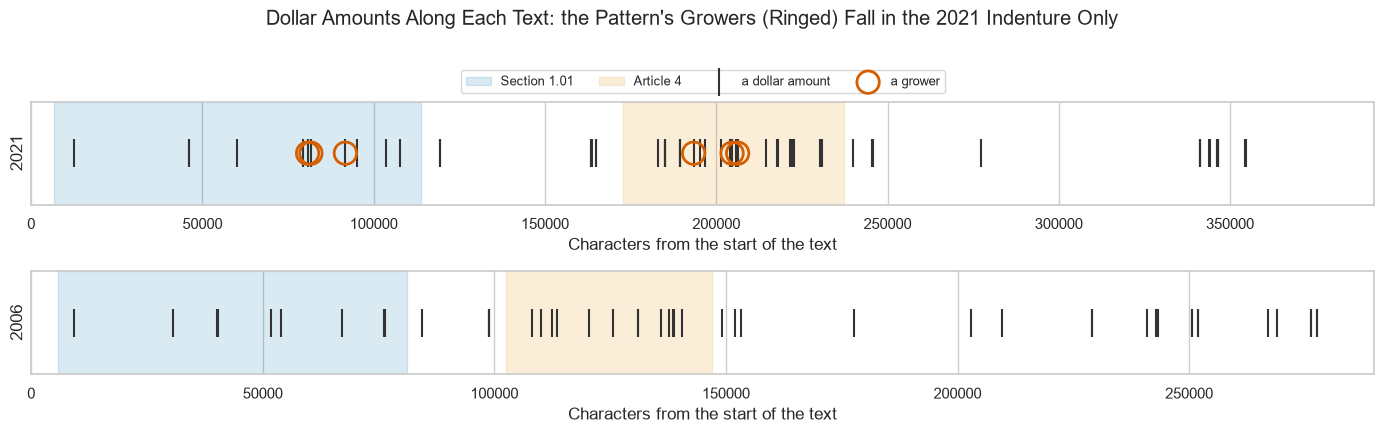

In [21]:
# every amount along each text by character position, growers ringed, Section 1.01 and Article 4 shaded
fig, axes = plt.subplots(2, 1, figsize=(14, 4.4))
for ax, doc in zip(axes, DOCS):
    text, sections, definitions = DOCS[doc]
    spans = sections.set_index("number")
    article = sections[sections["number"].str.startswith("4.")]
    ax.axvspan(spans.loc["1.01", "start"], spans.loc["1.01", "end"], color="C0", alpha=0.15, label="Section 1.01")
    ax.axvspan(article["start"].min(), article["end"].max(), color="C1", alpha=0.15, label="Article 4")
    starts = [found.start() for found in re.finditer(AMOUNT, text)]
    rings = [found.start("amount") for found in re.finditer(GROWER, text)]
    ax.scatter(starts, np.zeros(len(starts)), marker="|", s=400, color="0.2", label="a dollar amount")
    ax.scatter(rings, np.zeros(len(rings)), s=260, facecolors="none", edgecolors="C3", lw=2, label="a grower")
    ax.set(xlim=(0, len(text)), yticks=[], ylabel=VINTAGE[doc][:4], xlabel="Characters from the start of the text")
axes[0].legend(loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Dollar Amounts Along Each Text: the Pattern's Growers (Ringed) Fall in the 2021 Indenture Only")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

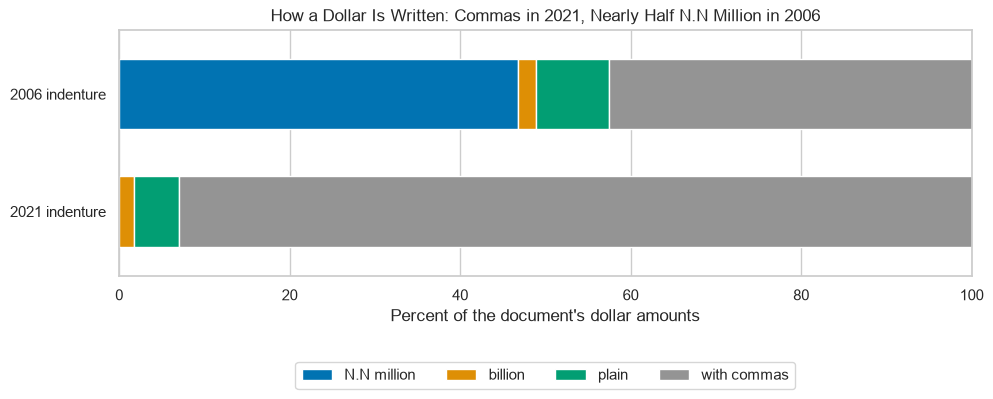

In [22]:
# the written forms as shares of each document's dollar amounts
shares = (forms / forms.sum() * 100).T
ax = shares.plot.barh(stacked=True, figsize=(11, 3.2), color=["C0", "C1", "C2", "C7"], width=0.6)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4)
ax.set(xlabel="Percent of the document's dollar amounts", xlim=(0, 100),
       title="How a Dollar Is Written: Commas in 2021, Nearly Half N.N Million in 2006")
plt.show()

**The pattern lists every amount it was written for; a reader still names the clause each one belongs to.**

# The Baskets Side by Side

## Three Clauses a Desk Reads First

A **credit facility basket** permits bank debt up to an amount; a **general basket** permits any debt or liens up to an amount, whatever the purpose.
A **fixed basket** states a dollar amount only; a **percentage-only basket** states a share of a defined measure and no dollar amount.

In [23]:
# source text: quoted as published
# the six clauses by name, each from the words that set its limit, line breaks shown as /
liens_2021 = clauses(boyd_definitions["Permitted Liens"], LETTERS)
liens_2006 = clauses(levi_definitions["Permitted Liens"], LETTERS)
PANEL = {("credit facility", "boyd"): ("4.12(b)(iii)", permissions["iii"]),
         ("credit facility", "levi"): ('"Permitted Debt" (b)', permitted_debt["b"]),
         ("general debt", "boyd"): ("4.12(b)(xv)", permissions["xv"]),
         ("general debt", "levi"): ('"Permitted Debt" (k)', permitted_debt["k"]),
         ("general liens", "boyd"): ('"Permitted Liens" (jj)', liens_2021["jj"]),
         ("general liens", "levi"): ('"Permitted Liens" (t)', liens_2006["t"])}
for (basket, doc), (clause, words) in PANEL.items():
    limit = re.search(r"(?:greater of|not to exceed|not in excess of).{0,140}", words.replace("\n", " / "))[0]
    print(f"{VINTAGE[doc]} | {basket} | {clause}: {limit}")
boyd_source()
levi_source()

2021 indenture | credit facility | 4.12(b)(iii): not to exceed the greater of (A) $3.5 billion, and (B) 4.5 times Consolidated EBITDA during the Reference Period, calculated on a Pro Forma Basis;
2006 indenture | credit facility | "Permitted Debt" (b): greater of: / (1) $1.6 billion, which amount shall be permanently reduced by the amount of Net Available Cash used to Repay Debt under the Credit / 41
2021 indenture | general debt | 4.12(b)(xv): not to exceed the greater of (A) $430,000,000 and (B) 7.5% of the Company's Consolidated Total Assets, calculated on a Pro Forma Basis;
2006 indenture | general debt | "Permitted Debt" (k): not to exceed $100.0 million; and
2021 indenture | general liens | "Permitted Liens" (jj): greater of $430,000,000 and 7.5% of the Company's Consolidated Total Assets at any one time outstanding as of the date any such Lien is granted or oth
2006 indenture | general liens | "Permitted Liens" (t): not in excess of 5.0% of Consolidated Net Tangible Assets, as d

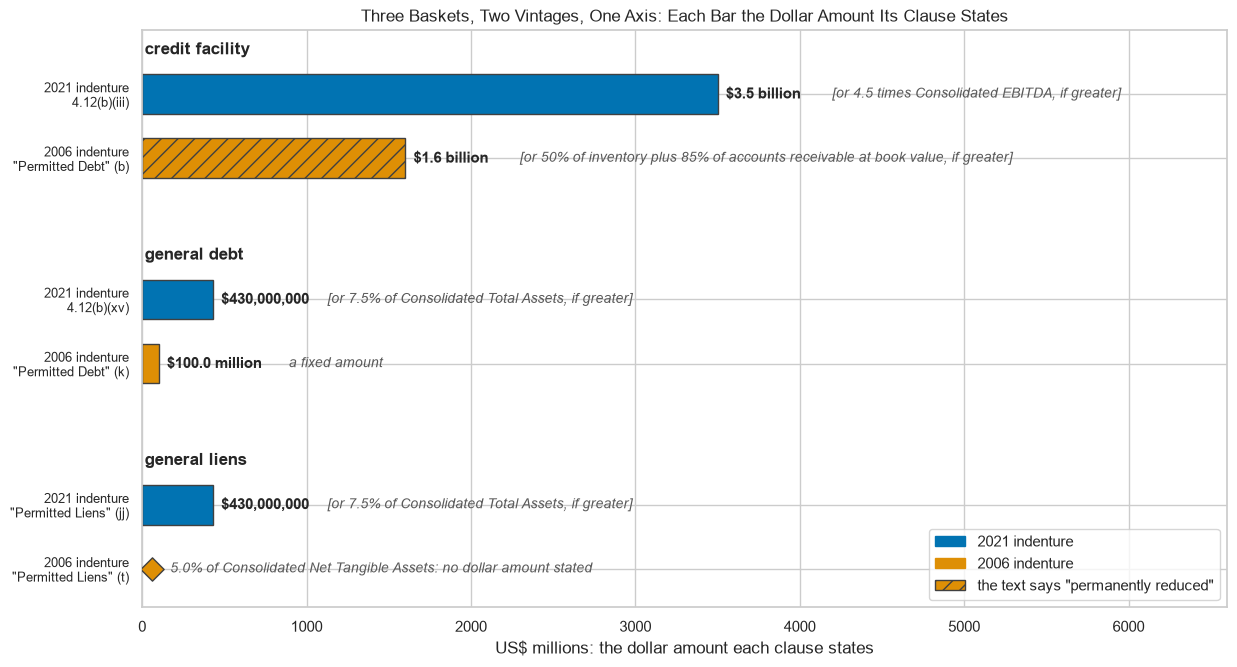

In [24]:
# the vintage panel: three baskets by two documents on one US$ axis, each bar the amount code reads in its clause
ALTERNATIVE = {("credit facility", "boyd"): "[or 4.5 times Consolidated EBITDA, if greater]",
               ("credit facility", "levi"): "[or 50% of inventory plus 85% of accounts receivable at book value, if greater]",
               ("general debt", "boyd"): "[or 7.5% of Consolidated Total Assets, if greater]",
               ("general debt", "levi"): "a fixed amount",
               ("general liens", "boyd"): "[or 7.5% of Consolidated Total Assets, if greater]"}
fig, ax = plt.subplots(figsize=(14, 7.5))
labels, ys = [], []
for row, (basket, doc) in enumerate(PANEL):
    clause, words = PANEL[basket, doc]
    y = -(row + row // 2 * 1.2)
    labels, ys = labels + [f"{VINTAGE[doc]}\n{clause}"], ys + [y]
    if row % 2 == 0:
        ax.text(15, y + 0.62, basket, fontsize=12, weight="bold")
    written = re.findall(AMOUNT, words)
    if written:
        amount, reduced = dollars(written[0]) / 1e6, "permanently reduced" in words
        ax.barh(y, amount, height=0.62, color="C0" if doc == "boyd" else "C1", edgecolor="0.25", hatch="//" if reduced else None)
        ax.text(amount + 50, y, written[0], va="center", fontsize=11, weight="bold")
        ax.text(amount + 120 + 48 * len(written[0]), y, ALTERNATIVE[basket, doc], va="center", fontsize=10, color="0.35", style="italic")
    else:
        ax.scatter(60, y, marker="D", s=140, color="C1", edgecolor="0.25", zorder=3)
        ax.text(170, y, "5.0% of Consolidated Net Tangible Assets: no dollar amount stated", va="center", fontsize=10, color="0.35", style="italic")
ax.set_yticks(ys, labels, fontsize=9)
keys = [plt.Rectangle((0, 0), 1, 1, color="C0"), plt.Rectangle((0, 0), 1, 1, color="C1"),
        plt.Rectangle((0, 0), 1, 1, facecolor="C1", edgecolor="0.25", hatch="//")]
ax.legend(keys, [VINTAGE["boyd"], VINTAGE["levi"], 'the text says "permanently reduced"'], loc="lower right")
ax.set(xlim=(0, 6600), ylim=(min(ys) - 0.6, 1.0), xlabel="US$ millions: the dollar amount each clause states",
       title="Three Baskets, Two Vintages, One Axis: Each Bar the Dollar Amount Its Clause States")
plt.show()

### Interpretation of the Panel

The 2021 indenture writes all three as the greater of a dollar amount and an alternative: a multiple of Consolidated EBITDA, or 7.5% of Consolidated Total Assets.

The 2006 indenture writes general debt as a fixed amount, general liens as 5.0% of Consolidated Net Tangible Assets alone.

Its credit facility amount is one the text says is "permanently reduced" by Net Available Cash used to repay that debt.

Neither document states an alternative's dollar value, so the panel draws none.

**The panel states what each document writes and where; it ranks nothing.**

# Two More Sentences

## The Day's Sentences

`TODAY` holds two sentences sent after Day 12's three.
The first asks a grower to fill both its numbers; the second asks a quote copied from a definition to cite 1.01, where Day 12's liens values cited 4.14.

In [25]:
# the day's two sentences, sent after Day 12's three, and the 4.12 message they make
TODAY = [("For a basket written as the greater of a dollar amount and a percentage of a defined term, fill both "
          "fixed_amount_usd and percent, put the defined term in percent_of, and set greater_of to true."),
         "A quote copied from a definition of Section 1.01 gives its section as 1.01."]
print([len(sentence) for sentence in TODAY], "characters |",
      len(covenant_message("4.12", "indebtedness", CHANGES + TODAY)), "characters in the 4.12 message")

[194, 75] characters | 42022 characters in the 4.12 message


## Section 4.12 Again

In [26]:
# LLM response
# Section 4.12 with all five sentences: why it stopped, its tokens, then its checked table
boyd_responses = {"4.12": extract("4.12", "indebtedness", CHANGES + TODAY)}
boyd_covenants = {"4.12": Covenant.model_validate(json.loads(boyd_responses["4.12"]["content"]))}
print(boyd_responses["4.12"]["finish_reason"], "|", boyd_responses["4.12"]["usage"]["prompt_tokens"], "prompt and",
      boyd_responses["4.12"]["usage"]["completion_tokens"], "completion tokens")
checks_412 = check_extraction(boyd_covenants["4.12"])
print(checks_412[["field", "value", "section", "number_found", "passed"]].to_string(index=False))
print(int(checks_412["passed"].sum()), "of", len(checks_412), "values pass")
llm_line(boyd_responses["4.12"])

stop | 9534 prompt and 741 completion tokens
                                 field        value section  number_found  passed
                            ratio_test          2.0    4.12          True    True
   Credit Facilities: fixed_amount_usd 3500000000.0    4.12          True    True
            Credit Facilities: percent          4.5    4.12         False   False
capital expenditures: fixed_amount_usd  285000000.0    4.12          True    True
         capital expenditures: percent          5.0    4.12          True    True
  other Indebtedness: fixed_amount_usd  430000000.0    4.12          True    True
           other Indebtedness: percent          7.5    4.12          True    True
6 of 7 values pass
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


All three baskets come back as growers with both numbers, and the credit facility's 4.5 multiple is in `percent` again, where the number check fails it.

Day 12's third sentence had emptied that field; today's first sentence undid it.

## Liens, Payments, Change of Control

A **restricted payment** is a dividend or other payout the covenant limits; Section 4.15 caps them at a **builder basket**, a running sum written (A) to (F).

In [27]:
# source text: quoted as published
# the six parts of Section 4.15's builder basket, the first 90 characters of each
for line in section_text(boyd, boyd_sections, "4.15").split("\n"):
    if re.match(r"\([A-F]\) ", line) and "Gaming" not in line:
        print(line[:90])
boyd_source("4.15")

(A) 50% of the Consolidated Net Income accrued during the period (treated as one accountin
(B) the aggregate proceeds received by the Company from the issue or sale of its Capital S
(C) the amount by which Indebtedness of the Company or any Restricted Subsidiary is reduce
(D) the amount equal to the net reduction in Investments that were treated as Restricted P
(E) payments of dividends, repayments of loans or advances or other transfers of assets to
(F) $50,000,000.
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.15.


In [28]:
# LLM response
# 4.14, 4.15 and 4.10 with all five sentences: tokens, baskets, values passed of checked, and the sections cited
for number, kind in [("4.14", "liens"), ("4.15", "restricted_payments"), ("4.10", "change_of_control")]:
    boyd_responses[number] = extract(number, kind, CHANGES + TODAY)
    boyd_covenants[number] = Covenant.model_validate(json.loads(boyd_responses[number]["content"]))
    table = check_extraction(boyd_covenants[number])
    print(number, boyd_responses[number]["usage"]["completion_tokens"], "completion tokens | baskets:",
          len(boyd_covenants[number].baskets), "|", int(table["passed"].sum()), "of", len(table), "pass | cited:",
          sorted(set(table["section"])))
boyd_checks = pd.concat([check_extraction(boyd_covenants[number]) for number in ["4.12", "4.14", "4.15"]], ignore_index=True)
llm_line(boyd_responses["4.14"])

4.14 977 completion tokens | baskets: 1 | 2 of 2 pass | cited: ['1.01']
4.15 1178 completion tokens | baskets: 6 | 2 of 2 pass | cited: ['4.15']
4.10 66 completion tokens | baskets: 0 | 0 of 0 pass | cited: []
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


4.14's two values now cite 1.01, where clause (jj) sits, and both pass.

4.15 returns the builder as six baskets, four of them with no number; 4.10 returns none, and its 101% repurchase price has no field (Day 12).

## Code's List Against the Model's

Code lists every amount and the response names the baskets, so each list is checked against the other.

In [29]:
# each section's amounts as code reads them, against the amounts of the response's baskets
for number in ["4.12", "4.15"]:
    returned = {basket.fixed_amount_usd for basket in boyd_covenants[number].baskets} - {None}
    listed = amounts_2021.loc[amounts_2021["section"] == number, "amount_usd"]
    print(number, "| code's amounts with a basket in the response:", int(listed.isin(returned).sum()), "of", len(listed),
          "| response amounts not on code's list:", sorted(returned - set(listed)))

4.12 | code's amounts with a basket in the response: 3 of 5 | response amounts not on code's list: []
4.15 | code's amounts with a basket in the response: 1 of 6 | response amounts not on code's list: []


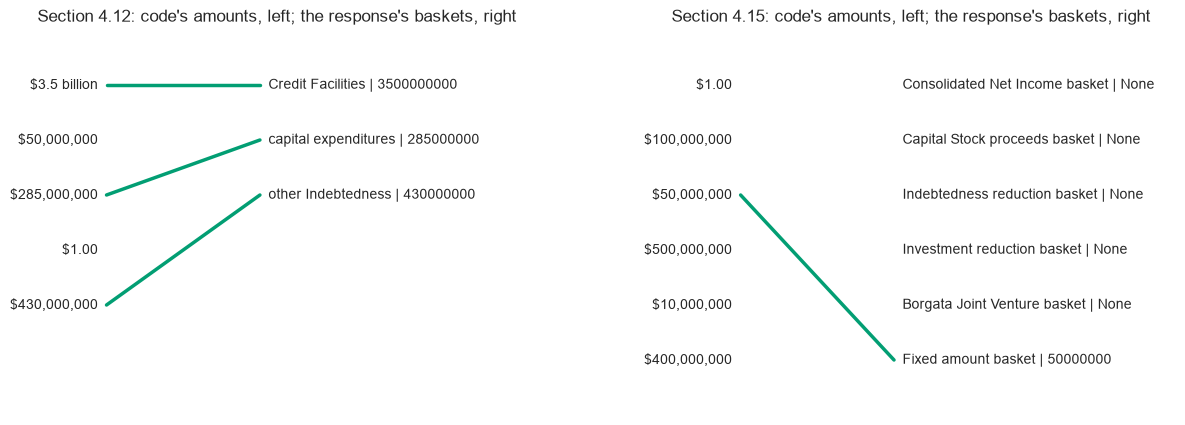

In [30]:
# code's amounts at left, the response's baskets at right, a line where both hold the same amount
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, number in zip(axes, ["4.12", "4.15"]):
    listed = amounts_2021.loc[amounts_2021["section"] == number, "written"].tolist()
    baskets = boyd_covenants[number].baskets
    for i, written in enumerate(listed):
        ax.text(0, -i, written, ha="right", va="center", fontsize=10)
        for j, basket in enumerate(baskets):
            if basket.fixed_amount_usd == dollars(written):
                ax.plot([0.05, 0.95], [-i, -j], color="C2", lw=2.5)
    for j, basket in enumerate(baskets):
        ax.text(1, -j, f"{basket.name[:34]} | {basket.fixed_amount_usd}", ha="left", va="center", fontsize=10)
    ax.set(xlim=(-0.5, 2.6), ylim=(-6, 1), title=f"Section {number}: code's amounts, left; the response's baskets, right")
    ax.set_axis_off()
plt.show()

In 4.12 the response leaves out `$50,000,000` of (viii) and the `$1.00` of (xiii); in 4.15 it returns one of code's six amounts.

Every amount the response does return is on code's list.

## Day 12's Prompt Against Today's

Day 12's saved responses to its three sentences, read from `day12`, never sent again.

In [31]:
# LLM response
# Day 12's three-sentence responses for 4.12, 4.14 and 4.15, then values passed of checked before and today
day12_responses, compare = {}, {}
for number, kind in [("4.12", "indebtedness"), ("4.14", "liens"), ("4.15", "restricted_payments")]:
    day12_responses[number] = ask(covenant_message(number, kind, CHANGES), max_tokens=4000, response_format=JSON_OBJECT,
                                  day="day12")
    before = check_extraction(Covenant.model_validate(json.loads(day12_responses[number]["content"])))
    after = check_extraction(boyd_covenants[number])
    compare[kind] = {"passed, Day 12": int(before["passed"].sum()), "checked, Day 12": len(before),
                     "passed, today": int(after["passed"].sum()), "checked, today": len(after)}
compare = pd.DataFrame(compare).T
print(compare.to_string())
llm_line(day12_responses["4.12"])

                     passed, Day 12  checked, Day 12  passed, today  checked, today
indebtedness                      6                6              6               7
liens                             0                2              2               2
restricted_payments               2                2              2               2
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


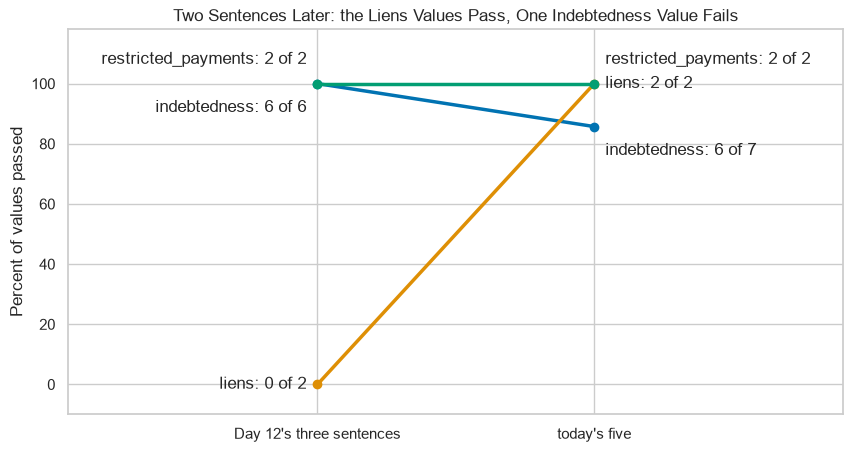

In [32]:
# Day 12's prompt to today's: the percent of values passed, one line a covenant
fig, ax = plt.subplots(figsize=(10, 5))
for i, (kind, row) in enumerate(compare.iterrows()):
    left, right = 100 * row["passed, Day 12"] / row["checked, Day 12"], 100 * row["passed, today"] / row["checked, today"]
    ax.plot([0, 1], [left, right], marker="o", lw=2.5, color=f"C{i}")
    ax.text(-0.04, left + 8 * (i - 1), f"{kind}: {row['passed, Day 12']} of {row['checked, Day 12']}", ha="right", va="center")
    ax.text(1.04, right + 8 * (i - 1), f"{kind}: {row['passed, today']} of {row['checked, today']}", ha="left", va="center")
ax.set(xticks=[0, 1], xticklabels=["Day 12's three sentences", "today's five"], xlim=(-0.9, 1.9), ylim=(-10, 118),
       ylabel="Percent of values passed", title="Two Sentences Later: the Liens Values Pass, One Indebtedness Value Fails")
plt.show()

**One sentence fixed a citation and another brought the multiple back; the checks show both.**

# The 2006 Indenture Through the Same Checks

## Four Requests

The same five sentences, schema and checks, with `doc="levi"`.

In [33]:
# LLM response
# the 2006 indenture's four covenants with all five sentences: why each stopped, and its tokens
levi_responses = {}
for kind in ["indebtedness", "liens", "restricted_payments", "change_of_control"]:
    number = KINDS[kind][1]
    levi_responses[number] = extract(number, kind, CHANGES + TODAY, doc="levi")
    print(number, kind, "|", levi_responses[number]["finish_reason"], "|",
          levi_responses[number]["usage"]["completion_tokens"], "completion tokens")
llm_line(levi_responses["4.04"])

4.04 indebtedness | stop | 711 completion tokens
4.06 liens | stop | 220 completion tokens
4.05 restricted_payments | stop | 2766 completion tokens
4.12 change_of_control | stop | 189 completion tokens
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


## A Response That Does Not Fit

In [34]:
# the 2006 liens covenant through the schema
Covenant.model_validate(json.loads(levi_responses["4.06"]["content"]))

ValidationError: 1 validation error for Covenant
quote
  Field required [type=missing, input_value={'kind': 'liens', 'sectio...cured by that Lien.'}}]}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.13/v/missing

The error names the class, `Covenant`, its missing field, `quote`, and "Field required": the response left out the covenant's own quote, though its baskets kept theirs.

**A response that does not fit the schema is not parsed: the 2006 liens covenant goes into the table as "not parsed".**

## Three That Parse

In [35]:
# LLM response
# the other three through the schema, and each basket's numbers as the response gives them
levi_covenants = {number: Covenant.model_validate(json.loads(levi_responses[number]["content"]))
                  for number in ["4.04", "4.05", "4.12"]}
for number, covenant in levi_covenants.items():
    print(number, covenant.kind, "| baskets:", len(covenant.baskets))
    for basket in covenant.baskets:
        print("   ", basket.name, "|", basket.fixed_amount_usd, "|", basket.percent, "|", basket.percent_of)
llm_line(levi_responses["4.04"])

4.04 indebtedness | baskets: 4
    Credit Facilities and related transactions | 1600000000 | None | None
    Inventory and accounts receivable | None | 50.0 | book value of the inventory of the Company and the Restricted Subsidiaries
    Inventory and accounts receivable | None | 85.0 | book value of the accounts receivable of the Company and the Restricted Subsidiaries
    General basket | 100000000 | None | None
4.05 restricted_payments | baskets: 8
    Consolidated Net Income basket | None | 50.0 | Consolidated Net Income
    Capital Stock Sale Proceeds basket | None | None | None
    Convertible/exchangeable Debt conversion basket | None | None | None
    Investment reduction basket | None | None | None
    Unrestricted Subsidiary designation basket | None | None | None
    Disqualified Stock dividends basket | None | None | None
    Public Equity Offering dividends basket | None | 6.0 | net cash proceeds received by the Company in such Public Equity Offering
    Share repurchase b

4.04 returns `$1.6 billion` as an amount alone, and the 50% and 85% of book value as two more baskets.

4.12, change of control, returns no basket.

**Predict 2**

The three parsed responses hold 8 numbers between them, a ratio test among them.

Q. With Day 12's checks unchanged, how many of the 8 will pass? Write down a number.

## The Checked Values

In [36]:
# LLM response
# Day 12's checks, unchanged, on the 2006 values
levi_checks = pd.concat([check_extraction(covenant, doc="levi") for covenant in levi_covenants.values()
                         if covenant_values(covenant)], ignore_index=True)
print(levi_checks[["covenant", "field", "value", "quote_found", "number_found", "passed"]].to_string(index=False))
print(int(levi_checks["passed"].sum()), "of", len(levi_checks), "values pass")
llm_line(levi_responses["4.04"])

           covenant                                                        field        value  quote_found  number_found  passed
       indebtedness                                                   ratio_test          2.0         True          True    True
       indebtedness Credit Facilities and related transactions: fixed_amount_usd 1600000000.0        False          True   False
       indebtedness                   Inventory and accounts receivable: percent         50.0         True          True    True
       indebtedness                   Inventory and accounts receivable: percent         85.0         True          True    True
       indebtedness                             General basket: fixed_amount_usd  100000000.0         True         False   False
restricted_payments                      Consolidated Net Income basket: percent         50.0         True          True    True
restricted_payments             Public Equity Offering dividends basket: percent          6.0    

`$100.0 million` and `$10.0 million` fail the number check: Day 12's forms write "100 million", never "100.0 million".

`$1.6 billion` fails the quote check, though its number is in its quote.

## A Form the 2006 Text Needs

From today `number_forms` adds one written form for an amount of US$1,000,000 or more, "N.N million", after Day 12's.

In [37]:
# Day 12's written forms, and one more from Day 13 on: millions with one decimal
def number_forms(value, unit):
    """The ways the text may write a number, with no dollar sign."""
    if unit == "USD":
        forms = [f"{int(value):,}"]
        if value >= 1e6:
            forms.append(f"{value / 1e6:,g} million")
        if value >= 1e9:
            forms.append(f"{value / 1e9:g} billion")
        if value >= 1e6:
            forms.append(f"{value / 1_000_000:,.1f} million")
    elif unit == "%":
        forms = [f"{value:g}%", f"{value:.1f}%"]
    else:
        forms = [f"{value:.1f} to 1.0", f"{value:.2f} to 1.00", f"{value:g} to 1"]
    return [form for i, form in enumerate(forms) if form not in forms[:i]]


print(number_forms(100_000_000, "USD"))

['100,000,000', '100 million', '100.0 million']


In [38]:
# LLM response
# the 2006 values checked again, and the 2021 values checked with the new form against their table before it
levi_checks = pd.concat([check_extraction(covenant, doc="levi") for covenant in levi_covenants.values()
                         if covenant_values(covenant)], ignore_index=True)
boyd_again = pd.concat([check_extraction(boyd_covenants[number]) for number in ["4.12", "4.14", "4.15"]], ignore_index=True)
print(int(levi_checks["passed"].sum()), "of", len(levi_checks), "2006 values pass | not passed:",
      levi_checks.loc[~levi_checks["passed"], "field"].tolist())
print("2021 table the same with the new form:", boyd_again.equals(boyd_checks))
llm_line(levi_responses["4.04"])

7 of 8 2006 values pass | not passed: ['Credit Facilities and related transactions: fixed_amount_usd']
2021 table the same with the new form: True
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


## A Page Number Inside a Sentence

`difflib.SequenceMatcher` lines up two lists of words, and its `.get_opcodes()` names each run: equal, insert, delete or replace, with where it sits in each list.

In [39]:
# source text: quoted as published
# the rejected quote against Section 4.04, word by word (a comma or semicolon ending a word set aside): where they differ
quote = next(basket.quote.text for basket in levi_covenants["4.04"].baskets if basket.fixed_amount_usd == 1_600_000_000)
quote_words = [word.rstrip(",;") for word in plain(quote).split()]
filed = plain(body_404)
filed_words = [word.rstrip(",;") for word in filed[filed.index(plain(quote)[:60]):].split()[:len(quote_words) + 1]]
runs = difflib.SequenceMatcher(None, quote_words, filed_words).get_opcodes()
print([(change, quote_words[a:b], filed_words[c:d]) for change, a, b, c, d in runs if change != "equal"])
print("lines that are only a number:", {VINTAGE[doc]: len(re.findall(r"^\d+$", text, flags=re.MULTILINE))
                                         for doc, (text, sections, definitions) in DOCS.items()})
levi_source("4.04")

[('insert', [], ['41'])]
lines that are only a number: {'2021 indenture': 101, '2006 indenture': 114}
Source: Levi Strauss & Co., Indenture dated as of March 17, 2006, 8-7/8% Senior Notes due 2016, Exhibit 4.1 to the 8-K filed 2006-03-17, accession 0000950134-06-005445, Section 4.04.


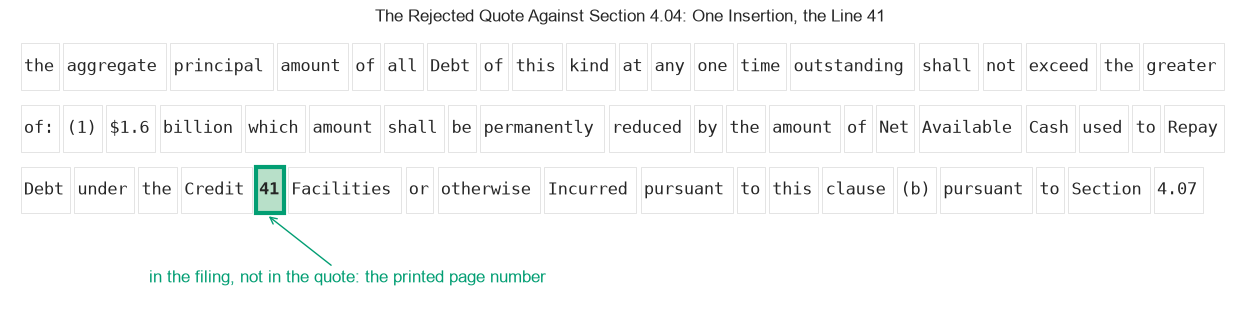

In [40]:
# source text: quoted as published
# the quote and the filing as one running text: the words both hold plain, the filing's extra line marked
fig, ax = plt.subplots(figsize=(16, 3.6))
x, y = 0, 0
for change, a, b, c, d in runs:
    for word in filed_words[c:d]:
        if x + len(word) > 112:
            x, y = 0, y - 1
        inserted = change == "insert"
        ax.add_patch(plt.Rectangle((x, y - 0.38), len(word) + 0.6, 0.76, facecolor="#B8E0C9" if inserted else "white",
                                   edgecolor="#029E73" if inserted else "0.85", lw=3 if inserted else 0.5))
        ax.text(x + 0.3, y, word, va="center", fontsize=12, family="monospace", weight="bold" if inserted else "normal")
        if inserted:
            ax.annotate("in the filing, not in the quote: the printed page number", xy=(x + 1, y - 0.4),
                        xytext=(x - 10, y - 1.5), color="#029E73", arrowprops={"arrowstyle": "->", "color": "#029E73"})
        x += len(word) + 1
ax.set(xlim=(-1, 115), ylim=(y - 1.9, 0.6), title="The Rejected Quote Against Section 4.04: One Insertion, the Line 41")
ax.set_axis_off()
plt.show()

The quote is 4.04's text word for word but for the line "41", the filing's page number between "Credit" and "Facilities".

Both texts hold over a hundred such lines, so any quote may cross one.

**A rejected value goes to a person with its quote; no document gets a check of its own.**

# One Comparable Table

## Checked Values by Kind

In [41]:
# LLM response
# every checked value of both documents by covenant kind: values passed of values checked, then the passed values
both = pd.concat([boyd_checks.assign(document=VINTAGE["boyd"]), levi_checks.assign(document=VINTAGE["levi"])],
                 ignore_index=True)
summary = both.groupby(["covenant", "document"], sort=False)["passed"].agg(lambda passed: f"{int(passed.sum())} of {len(passed)} pass")
summary = summary.unstack().reindex(["indebtedness", "liens", "restricted_payments", "change_of_control"])
summary.loc["liens", VINTAGE["levi"]] = "not parsed"
summary.loc["change_of_control"] = "nothing to check"
print(summary.to_string())
print(both.loc[both["passed"], ["document", "covenant", "field", "value", "section"]].to_string(index=False))
llm_line(levi_responses["4.04"])

document               2021 indenture    2006 indenture
covenant                                               
indebtedness              6 of 7 pass       4 of 5 pass
liens                     2 of 2 pass        not parsed
restricted_payments       2 of 2 pass       3 of 3 pass
change_of_control    nothing to check  nothing to check
      document            covenant                                            field        value section
2021 indenture        indebtedness                                       ratio_test          2.0    4.12
2021 indenture        indebtedness              Credit Facilities: fixed_amount_usd 3500000000.0    4.12
2021 indenture        indebtedness           capital expenditures: fixed_amount_usd  285000000.0    4.12
2021 indenture        indebtedness                    capital expenditures: percent          5.0    4.12
2021 indenture        indebtedness             other Indebtedness: fixed_amount_usd  430000000.0    4.12
2021 indenture        indebtedness

## Your Turn: One Kind at a Time

Pick a covenant kind to see both documents' checked values side by side.

In [42]:
# one kind's checked values for both documents: yes in blue and no in orange
def draw_kind(kind="indebtedness"):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    for ax, document in zip(axes, VINTAGE.values()):
        rows = both[(both["covenant"] == kind) & (both["document"] == document)]
        if len(rows):
            grid = rows.set_index("field")[["section_exists", "quote_found", "number_found"]].astype(int)
            sns.heatmap(grid, annot=grid.replace({1: "yes", 0: "no"}), fmt="", cmap=["#DE8F05", "#56B4E9"], vmin=0, vmax=1,
                        cbar=False, linewidths=1, ax=ax)
        else:
            ax.set_axis_off()
        ax.set(ylabel="", title=f"{document}, {kind}: {summary.loc[kind, document]}")
    plt.tight_layout()
    plt.show()


interact(draw_kind, kind=list(summary.index));

interactive(children=(Dropdown(description='kind', options=('indebtedness', 'liens', 'restricted_payments', 'c…

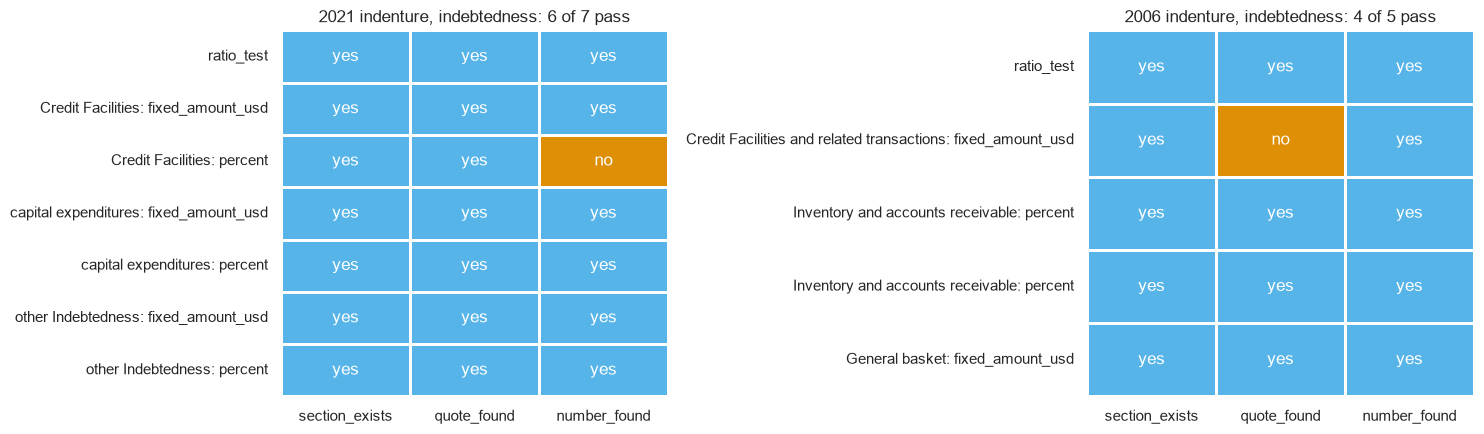

In [43]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_kind(kind="indebtedness")

**The table says what each document writes, with its section, and nothing about either.**

# A PDF Page

## The Text Layer

A **PDF** stores each page as drawing instructions; most also carry a **text layer**, the page's characters, which `PdfReader` reads with `.pages` and `.extract_text()`.
Pages are counted from 0, the **page index**; the number printed at a page's foot is the filing's own.

In [44]:
# every page's text layer, read once and kept raw, then each page through normalize_text
reader = PdfReader(data_file("course7_boyd_2021_indenture.pdf"))
raw_pages = [page.extract_text() for page in reader.pages]
pages = [normalize_text(page) for page in raw_pages]
print(len(pages), "pages | pages holding '2029 and thereafter':",
      [i for i, page in enumerate(pages) if "2029 and thereafter" in page])

132 pages | pages holding '2029 and thereafter': [51, 109]


In [45]:
# source text: quoted as published
# page index 51: its size, the sections it holds, then the page from its table to its last line
print(len(pages[51]), "characters,", len(pages[51].split()), "words | sections:",
      re.findall(r"^Section (\d+\.\d+)\.", pages[51], flags=re.MULTILINE))
print(pages[51][pages[51].index("Year"):])
pdf_source(51)

3085 characters, 527 words | sections: ['3.04', '3.05', '3.06', '3.07']
Year Percentage
2026 102.375%
2027 101.583%
2028 100.792%
2029 and thereafter 100.000%
47
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, the course's PDF print of the SEC copy, page index 51 (pages counted from 0).


Page index 51 is the filing's page 47: Section 3.07's redemption table sits at its foot, and again on page 109, in the form of note.

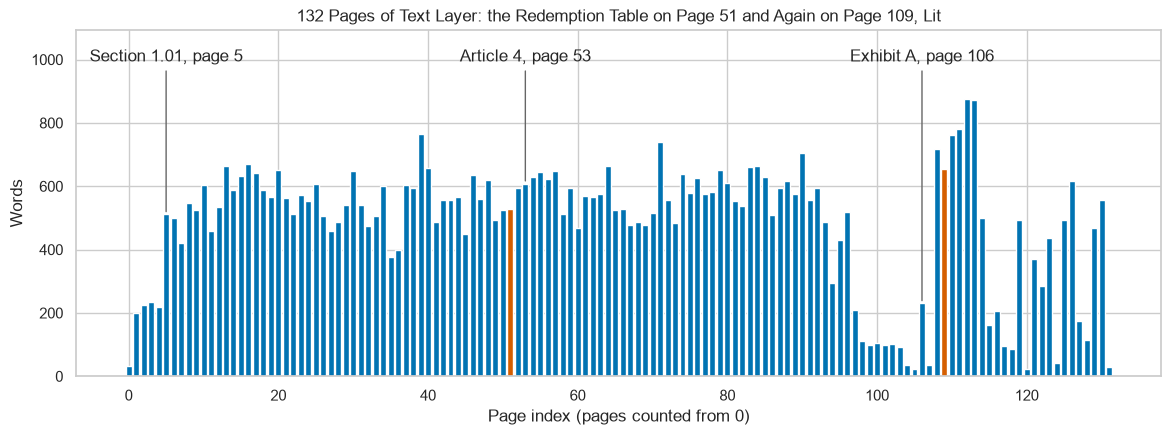

In [46]:
# words per page over the 132 pages, the two table pages lit, three starts labelled
page_words = [len(page.split()) for page in pages]
starts = {"Section 1.01": [i for i, page in enumerate(pages) if re.search(r"^Section 1\.01\. ", page, flags=re.M)][-1],
          "Article 4": [i for i, page in enumerate(pages) if re.search(r"^ARTICLE 4", page, flags=re.M)][-1],
          "Exhibit A": [i for i, page in enumerate(pages) if "EXHIBIT A" in page][0]}
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(range(len(pages)), page_words, color=["C3" if i in (51, 109) else "C0" for i in range(len(pages))])
for label, page in starts.items():
    ax.annotate(f"{label}, page {page}", xy=(page, page_words[page]), xytext=(page, max(page_words) + 120), ha="center",
                arrowprops={"arrowstyle": "-", "color": "0.4"})
ax.set(xlabel="Page index (pages counted from 0)", ylabel="Words", ylim=(0, max(page_words) + 220),
       title="132 Pages of Text Layer: the Redemption Table on Page 51 and Again on Page 109, Lit")
plt.show()

**Predict 3**

The `.txt` file, made by Day 9's route from the filed HTML, holds none of the nine look-alike characters of Day 1's map.

Q. How many does the PDF's raw text layer of the same document hold? Write down a number.

## Look-Alikes in the Text Layer

In [47]:
# source text: quoted as published
# the nine look-alikes of Day 1's map in the raw text layer, by name, then the .txt, the fraction slash and the words
in_pdf = {unicodedata.name(char): sum(page.count(char) for page in raw_pages) for char in CHARACTER_MAP}
print({name: count for name, count in in_pdf.items() if count})
print("look-alikes in the PDF:", sum(in_pdf.values()), "| in the .txt:", sum(boyd.count(char) for char in CHARACTER_MAP))
print("FRACTION SLASH in the PDF:", sum(page.count(chr(0x2044)) for page in raw_pages), "| in the .txt:", boyd.count(chr(0x2044)))
print("words through normalize_text:", sum(page_words), "| in the .txt:", len(boyd.split()))

{'EN DASH': 3, 'RIGHT SINGLE QUOTATION MARK': 180, 'LEFT DOUBLE QUOTATION MARK': 317, 'RIGHT DOUBLE QUOTATION MARK': 317}
look-alikes in the PDF: 817 | in the .txt: 0
FRACTION SLASH in the PDF: 1 | in the .txt: 1
words through normalize_text: 63593 | in the .txt: 63595


The text layer writes curly quotes, apostrophes and three en dashes; `normalize_text` makes them plain.

The fraction slash of "66 2/3%" is in both, one each, as Day 1 found it in the `.txt`.

## The Table, Row by Row

In [48]:
# source text: quoted as published
# the redemption rows of page 51 and of Section 3.07 in the .txt, as (year, percentage) pairs
TABLE_ROW = r"^(\d{4}(?: and thereafter)?) (\d+\.\d+%)$"
page_rows = re.findall(TABLE_ROW, pages[51], flags=re.MULTILINE)
text_rows = re.findall(TABLE_ROW, section_text(boyd, boyd_sections, "3.07"), flags=re.MULTILINE)
print(page_rows)
print(sum(a == b for a, b in zip(page_rows, text_rows)), "of", len(text_rows), "rows equal Section 3.07's")
boyd_source("3.07")

[('2026', '102.375%'), ('2027', '101.583%'), ('2028', '100.792%'), ('2029 and thereafter', '100.000%')]
4 of 4 rows equal Section 3.07's
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 3.07.


## The Page as an Image

`pypdfium2` draws a page in pixels: `.render(scale=2.0)` at twice the PDF's own size, `.to_pil()` as a Pillow image.
`io.BytesIO` keeps the PNG bytes in memory, and `.getvalue()` returns them.

In [49]:
# page index 51 drawn at twice its size, saved as PNG bytes in memory, and its fingerprint
page_image = pypdfium2.PdfDocument(data_file("course7_boyd_2021_indenture.pdf"))[51].render(scale=2.0).to_pil()
buffer = io.BytesIO()
page_image.save(buffer, format="PNG")
png = buffer.getvalue()
print(page_image.size, "pixels |", len(png), "bytes | SHA-256", hashlib.sha256(png).hexdigest()[:12])

(1224, 1584) pixels | 289865 bytes | SHA-256 5d71083c6d83


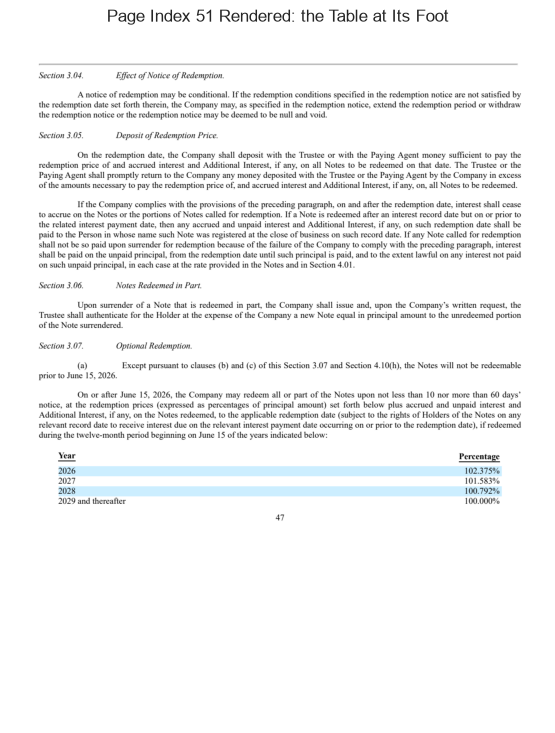

In [50]:
# the page as the PDF draws it
fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(page_image)
ax.set_axis_off()
ax.set_title("Page Index 51 Rendered: the Table at Its Foot")
plt.show()

The saved response replays only when this render is the course's byte for byte, as it is on pypdfium2 5.14.0 and Pillow 12.3.0.

## An Image Message

An **image message** sends a page as pixels: its content is a list of two **content parts**, a `text` part with the question and an `image_url` part with the picture.
The picture travels as a data URL, Course 3's data URI: `base64.b64encode` writes the PNG bytes as text.
An **image model** takes both parts; the course's is a free one on OpenRouter.

In [51]:
# the question, the page as a data URL, and the two content parts
IMAGE_MODEL = "nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free"
IMAGE_PROMPT = ('This page image holds a table of redemption prices. Return one JSON object {"rows": [{"year": text, '
                '"percentage": text}]} with every row of the table, each written exactly as on the page.')
data_url = "data:image/png;base64," + base64.b64encode(png).decode("ascii")
content = [{"type": "text", "text": IMAGE_PROMPT}, {"type": "image_url", "image_url": {"url": data_url}}]
print([part["type"] for part in content], "|", len(IMAGE_PROMPT), "characters of text |", len(data_url),
      "characters of data URL")

['text', 'image_url'] | 187 characters of text | 386510 characters of data URL


**Predict 4**

Page 51's text layer is 3,085 characters and 527 words; Section 4.12's message of 42,022 characters billed 9,534 prompt tokens.

Q. How many prompt tokens does the image request bill? Write down a number.

## What Came Back

In [52]:
# LLM response
# the page sent to the image model with no response_format: why it stopped, its tokens, and its text
image_response = ask(content, model=IMAGE_MODEL, max_tokens=800)
print(image_response["finish_reason"], "|", image_response["usage"]["prompt_tokens"], "prompt and",
      image_response["usage"]["completion_tokens"], "completion tokens")
print(normalize_text(image_response["content"]))
llm_line(image_response)

stop | 2119 prompt and 125 completion tokens
```json
{
"rows": [
{
"year": "2026",
"percentage": "102.375%"
},
{
"year": "2027",
"percentage": "101.583%"
},
{
"year": "2028",
"percentage": "100.792%"
},
{
"year": "2029 and thereafter",
"percentage": "100.000%"
}
]
}
```
Model nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The response sits inside a **code fence**: three backquotes and a language name before it, three after.
`str.removeprefix` and `str.removesuffix` drop a known start and end, after `.strip()` removes the opening line break.

In [53]:
# LLM response
# the fence removed, the JSON parsed, and its rows held by two small classes, then compared with Section 3.07's
class Row(BaseModel):
    """One row of a redemption table, as the page writes it."""
    year: str
    percentage: str


class Table(BaseModel):
    """Every row of a redemption table."""
    rows: list[Row]


unfenced = image_response["content"].strip().removeprefix("```json").removesuffix("```")
image_rows = [(row.year, row.percentage) for row in Table.model_validate(json.loads(unfenced)).rows]
print(sum(a == b for a, b in zip(image_rows, text_rows)), "of", len(text_rows), "rows equal Section 3.07's")
llm_line(image_response)

4 of 4 rows equal Section 3.07's
Model nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The text requests asked for one JSON object through `response_format` and came back bare; this request sent none and came back fenced.

One page as pixels billed 2,119 prompt tokens, against 3,085 characters as text.

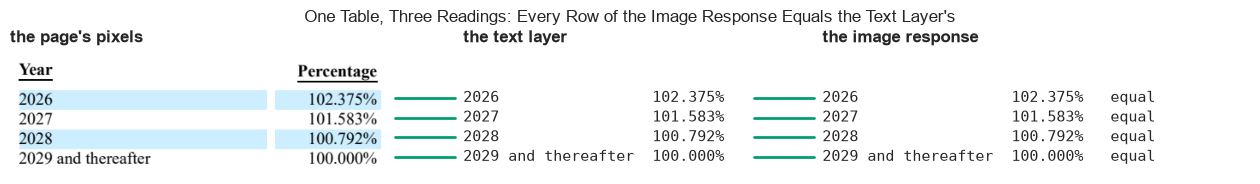

In [54]:
# the facsimile alignment: the render's year and percentage columns, the text layer's rows, the image response's rows
# .crop((left, top, right, bottom)) cuts a box of pixels from an image: here the table's two columns on page 51
# extent=(left, right, bottom, top) sets where imshow places an image on the axes
years, percents = page_image.crop((100, 955, 400, 1092)), page_image.crop((1000, 955, 1130, 1092))
fig, ax = plt.subplots(figsize=(16, 3.4))
ax.imshow(years, extent=(0, 300, 137, 0))
ax.imshow(percents, extent=(310, 440, 137, 0))
for pixels, layer, returned in zip([51, 74, 97, 120], page_rows, image_rows):
    ax.plot([450, 520], [pixels, pixels], color="C2", lw=2)
    ax.text(530, pixels, f"{layer[0]:20} {layer[1]}", va="center", fontsize=11, family="monospace")
    ax.plot([870, 940], [pixels, pixels], color="C2", lw=2)
    ax.text(950, pixels, f"{returned[0]:20} {returned[1]}   " + ("equal" if layer == returned else "differs"), va="center",
            fontsize=11, family="monospace")
for x, words in [(0, "the page's pixels"), (530, "the text layer"), (950, "the image response")]:
    ax.text(x, -14, words, weight="bold")
ax.set(xlim=(0, 1450), ylim=(140, -28), aspect="equal", title="One Table, Three Readings: Every Row of the Image Response Equals the Text Layer's")
ax.set_axis_off()
plt.show()

**Pixels came back as the filed table, and only the filed text could say so.**

# Which Route When

## Three Routes, One Table

The **route from text** reads the filing's HTML or the PDF's text layer; the **route from pixels** sends an image of the page.

In [55]:
# the three routes to Section 3.07's table: requests sent and rows read
routes = pd.DataFrame({"route": ["the filed HTML, as the .txt", "the PDF's text layer", "the page as an image"],
                       "requests": [0, 0, 1], "rows read": [len(text_rows), len(page_rows), len(image_rows)],
                       "rows equal to the .txt": [len(text_rows), sum(a == b for a, b in zip(page_rows, text_rows)),
                                                  sum(a == b for a, b in zip(image_rows, text_rows))]})
print(routes.to_string(index=False))

                      route  requests  rows read  rows equal to the .txt
the filed HTML, as the .txt         0          4                       4
       the PDF's text layer         0          4                       4
       the page as an image         1          4                       4


**Text layer first**: an image only when a PDF has no text layer, or one out of reading order, and its rows checked against text wherever text exists.

## Every Request of the Day

In [56]:
# the day's nine own requests: prompt and completion tokens, what they were billed, and their cost at the fallback's list prices
own = {"2021 " + number: response for number, response in boyd_responses.items()}
own.update({"2006 " + number: response for number, response in levi_responses.items()})
own["page 51 as an image"] = image_response
tokens = pd.DataFrame({name: {"prompt": response["usage"]["prompt_tokens"],
                              "completion": response["usage"]["completion_tokens"]} for name, response in own.items()}).T
prompt_price, completion_price = PRICES[FALLBACK_MODEL]
cost = tokens["prompt"].sum() * float(prompt_price) + tokens["completion"].sum() * float(completion_price)
print(tokens.sum().to_dict(), f"| US${cost:.7f} at the fallback's list prices | billed:",
      sorted({response["usage"]["cost"] for response in own.values()}))

{'prompt': 54849, 'completion': 6973} | US$0.0082741 at the fallback's list prices | billed: [0]


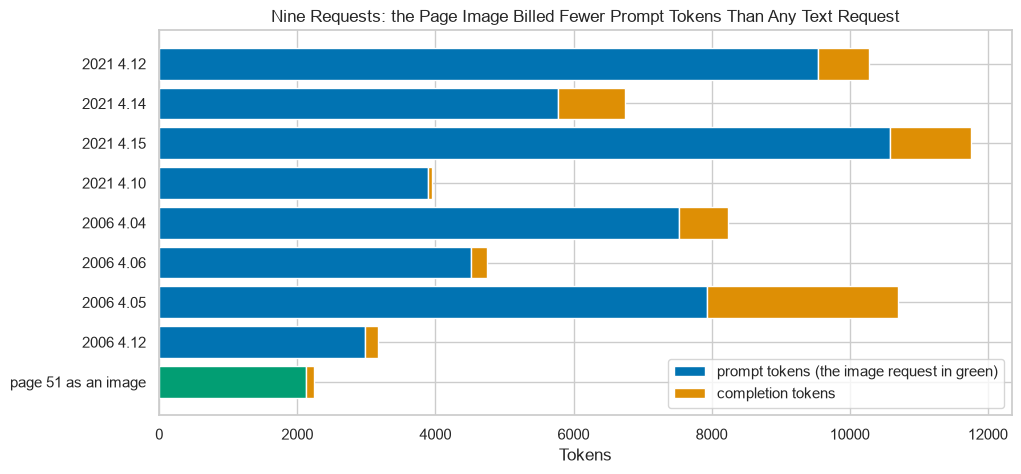

In [57]:
# the nine requests as stacked bars of prompt and completion tokens, the image request in green
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(tokens.index, tokens["prompt"], color=["C2" if name.startswith("page") else "C0" for name in tokens.index],
        label="prompt tokens (the image request in green)")
ax.barh(tokens.index, tokens["completion"], left=tokens["prompt"], color="C1", label="completion tokens")
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.set(xlabel="Tokens", title="Nine Requests: the Page Image Billed Fewer Prompt Tokens Than Any Text Request")
plt.show()

All nine were billed nothing on the free models; the course's figure is their cost at the fallback's list prices.

**Read text where there is text; check pixels against it.**

# Insights and Conclusion

Code lists 57 dollar amounts and 6 growers in the 2021 indenture, 47 amounts and no grower the pattern reads in the 2006 one, which writes "greater of:" with a colon.

The 2021 general baskets are growers; the 2006 general debt basket is fixed, its liens basket a share of Consolidated Net Tangible Assets.

One new sentence moved the liens citations to 1.01, the other brought the 4.5 multiple back into `percent`.

With "N.N million", 10 of 11 values pass in 2021 and 7 of 8 in 2006; the 2006 liens response did not parse.

The one 2006 rejection is a quote that skips the printed page number "41".

The text layer and the page image both returned the filed table, four rows of four.

**Code lists, the model names, the checks decide, on any vintage and any format with text in it.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Read a covenant as a prohibition, a ratio test, permissions and carve-outs, and find each clause by its label.
* List every dollar amount and grower basket of an indenture with a regular expression.
* Set two indentures' baskets side by side on one axis, and check a model's baskets against code's list.
* Run a second indenture through the same schema and checks, and add a written form of a number it needs.
* Read a PDF's text layer, send a page as an image, and check every row against the filed text.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [58]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Asset Sales in Both Documents**

Q. Extract each document's asset sales covenant with `extract`, kind `"asset_sales"`, `CHANGES + TODAY` and the section `KINDS` gives, and check it with `check_extraction`. Store the number of values that pass in each, 2021 first, as a list in `ex1_passed`.

In [59]:
# LLM response
# each document's asset sales covenant with all five sentences, checked with the day's forms
asset_sales = {doc: extract(KINDS["asset_sales"][i], "asset_sales", CHANGES + TODAY, doc=doc) for i, doc in enumerate(["boyd", "levi"])}
ex1_passed = []
for doc, response in asset_sales.items():
    table = check_extraction(Covenant.model_validate(json.loads(response["content"])), doc=doc)
    ex1_passed.append(int(table["passed"].sum()))
    print(VINTAGE[doc], "|", int(table["passed"].sum()), "of", len(table), "pass |", table["value"].tolist())
llm_line(asset_sales["levi"])

2021 indenture | 2 of 2 pass | [285000000.0, 5.0]
2006 indenture | 1 of 1 pass | [10000000]
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0.0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


The 2006 value is `$10.0 million`: Day 12's forms alone would fail it, and the day's "N.N million" form passes it.

In [60]:
check("Exercise 1 the values that pass in each document", ex1_passed, [2, 1])

Exercise 1 the values that pass in each document: correct


### Exercise 2

**The 2006 Redemption Schedule, by Text**

The 2006 indenture's redemption prices sit in its form of note, printed after the heading of Section 10.13, the last section, which `find_sections` runs to the end of the text; a citation names the form of note, never Section 10.13.

Q. Find the first schedule's four rows with a regular expression (the 2006 text puts a space before "%"). Store them as a list of (year, percentage) tuples of text in `ex2_schedule`, and the section `find_sections` places them in, as text, in `ex2_section`.

In [61]:
# source text: quoted as published
# the 2006 schedule's rows (a space before the percent sign), and the section find_sections places the first one in
schedule = list(re.finditer(r"^(\d{4}(?: and thereafter)?) (\d+\.\d+) %$", levi, flags=re.MULTILINE))
ex2_schedule = [found.groups() for found in schedule[:4]]
ex2_section = levi_sections.loc[levi_sections["start"] <= schedule[0].start(), "number"].iloc[-1]
print(ex2_schedule)
print(len(schedule), "rows in all | section", ex2_section)
levi_source()

[('2011', '104.438'), ('2012', '102.958'), ('2013', '101.479'), ('2014 and thereafter', '100.000')]
8 rows in all | section 10.13
Source: Levi Strauss & Co., Indenture dated as of March 17, 2006, 8-7/8% Senior Notes due 2016, Exhibit 4.1 to the 8-K filed 2006-03-17, accession 0000950134-06-005445.


The text prints the schedule twice, both times after Section 10.13's heading, in the form of note.

In [62]:
check("Exercise 2 the schedule", ex2_schedule, [("2011", "104.438"), ("2012", "102.958"), ("2013", "101.479"), ("2014 and thereafter", "100.000")])
check("Exercise 2 the section find_sections gives", ex2_section, "10.13")

Exercise 2 the schedule: correct
Exercise 2 the section find_sections gives: correct


### Exercise 3

**What Kind of Basket**

Q. Write `basket_kind(basket)`, a plain function with a one-line docstring that returns "greater of" when `greater_of` is true, else "fixed" when `fixed_amount_usd` is set, else "percent" when `percent` is set, else "none". Count the kinds over every basket in `boyd_covenants` and `levi_covenants`, as a dictionary of kind to count, in `ex3_kinds`.

In [63]:
# the kind of one basket, then the kinds of every basket the seven parsed covenants hold
def basket_kind(basket):
    """The kind of a basket: greater of, fixed, percent or none."""
    if basket.greater_of:
        return "greater of"
    if basket.fixed_amount_usd is not None:
        return "fixed"
    if basket.percent is not None:
        return "percent"
    return "none"


baskets = [basket for covenant in list(boyd_covenants.values()) + list(levi_covenants.values()) for basket in covenant.baskets]
ex3_kinds = pd.Series([basket_kind(basket) for basket in baskets]).value_counts().sort_index().to_dict()
print(len(baskets), "baskets |", ex3_kinds)

22 baskets | {'fixed': 4, 'greater of': 4, 'none': 9, 'percent': 5}


The four greater-of baskets are all the 2021 indenture's, in 4.12 and 4.14; "none" is the restricted payments baskets with no number.

In [64]:
check("Exercise 3 the kinds", ex3_kinds, {"fixed": 4, "greater of": 4, "none": 9, "percent": 5})

Exercise 3 the kinds: correct


### Exercise 4: AI check

**A Dollar Pattern That Stops Short**

You asked an AI assistant for a function that lists the dollar amounts in a sentence.
Run it on clause (t) of the 2021 "Permitted Investment" and on clause (b) of the 2006 "Permitted Debt".

In [65]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def dollar_amounts(sentence):
    """Every dollar amount in a sentence, in whole dollars."""
    return [int(found) for found in re.findall(r"\$(\d+)", sentence)]

In [66]:
# the helper on the two clauses
investments = clauses(boyd_definitions["Permitted Investment"], LETTERS)
print("2021 Permitted Investment (t):", dollar_amounts(investments["t"]))
print("2006 Permitted Debt (b):", dollar_amounts(permitted_debt["b"]))

2021 Permitted Investment (t): [855]
2006 Permitted Debt (b): [1]


The bug: `\$(\d+)` stops at the first comma or full stop, so the clause's 855,000,000 reads as 855 and 1.6 billion as 1.

A number check against these values would reject a basket the model returned correctly.

The fix: read each amount whole with `AMOUNT`, then turn it into dollars with `dollars`.

Q. Fix the one wrong idea, run the fixed function on the same two clauses, and store both results in one list, the 2021 clause's first, in `ex4_amounts`.

In [67]:
# the fix: AMOUNT reads the commas, the decimals and the scale word, and dollars turns each into whole dollars
def dollar_amounts(sentence):
    """Every dollar amount in a sentence, in whole dollars."""
    return [dollars(written) for written in re.findall(AMOUNT, sentence)]


ex4_amounts = dollar_amounts(investments["t"]) + dollar_amounts(permitted_debt["b"])
print(ex4_amounts)

[855000000, 1600000000]


In [68]:
check("Exercise 4 the amounts", ex4_amounts, [855000000, 1600000000])

Exercise 4 the amounts: correct


## Congratulations!

You set a 2006 indenture beside a 2021 one and read every dollar amount in both with your own patterns.
You drew their baskets on one axis, ran the older document through the same checks, and gave the number check the form it needed.
You traced a rejection to a page number inside a sentence, then read a table from a PDF page's pixels and checked every row.
That is the week's habit at full width: code lists, the model names, and the checks decide.
In Day 14 you retrieve the passages a question needs from the whole indenture, and check that every answer stays inside them.

[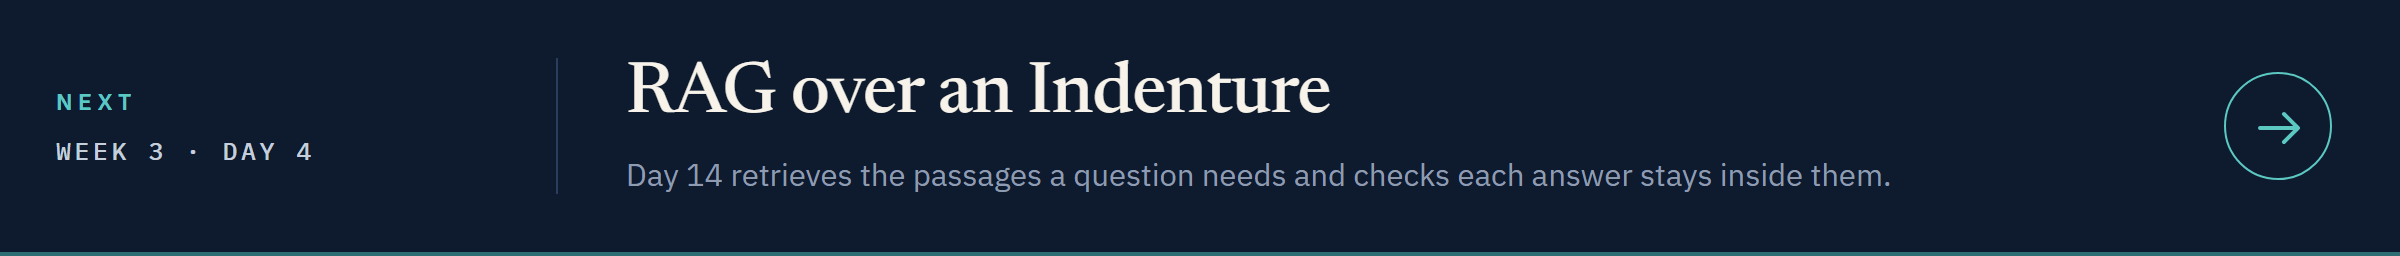](../day4/14_rag_over_an_indenture.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week3/day4/14_rag_over_an_indenture.ipynb)